# EXP-DENSENET121-TRANSFER-5SEEDS-022 — Split (10)

New five-seed DenseNet121 ImageNet transfer training run, using the EXP-018
architecture and two-stage recipe but **new weights and a new result namespace**.
The frozen inputs are `CashewData_Split (10).zip` and
`RL_Cashew_holdout (4).zip`.

Run all cells once, in order. The notebook audits both ZIPs, runs pipeline
smoke checks, trains all five seeds, writes a Validation-only checkpoint and
deployment selection lock, then runs Final Test and the external holdout.
Test and holdout predictions never select a seed, stage, threshold or
hyperparameter. Existing completed evaluation outputs are read back on rerun.

Split (10): Train 4,920, Val 1,445, Test 686. Holdout (4): 120 images in four
true classes; `not_cashew_leaf` remains a possible prediction but has no true
support. These two evaluation sets have different class support and are
reported separately.

Colab locates the project shortcut in the active account's My Drive. Set
`FORCE_REMOUNT_DRIVE=True` if the runtime still mounts the previous account.
Use the Drive path overrides if the shortcut has a custom location or the
shared project is read-only.

**Status:** code prepared; model training and numerical results pending.


In [1]:
import sys
print("Python:", sys.executable)

!nvidia-smi

Python: /usr/bin/python3
Tue Oct 27 14:04:56 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA RTX PRO 6000 Blac...    Off |   00000000:05:00.0 Off |                    0 |
| N/A   33C    P0             85W /  600W |    1101MiB /  97887MiB |      0%      Default |
|                                         |                        |             Disabled |
+----------------------

In [2]:

# ============================================================
# 01. IMPORT LIBRARIES
# ============================================================

import os
import sys
import io
import gc
import json
import time
import random
import shutil
import platform
import zipfile
import hashlib
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    ConfusionMatrixDisplay,
)

from IPython.display import display
import ipywidgets as widgets

MATRIX_CMAP = LinearSegmentedColormap.from_list(
    "readable_blues", ["#ffffff", "#dbeafe", "#93c5fd"]
)

plt.rcParams.update({
    "text.color": "black", "axes.labelcolor": "black",
    "axes.titlecolor": "black", "xtick.color": "black", "ytick.color": "black",
})

print("Imports completed.")


Imports completed.


In [3]:

# ============================================================
# 02. ENVIRONMENT INFORMATION
# ============================================================

print(f"Date              : {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")
print(f"Python            : {sys.version.split()[0]}")
print(f"TensorFlow        : {tf.__version__}")
print(f"Keras             : {keras.__version__ if hasattr(keras, '__version__') else 'tf.keras'}")
RUNTIME = ("Windows" if os.name == "nt" else "Kaggle" if Path("/kaggle/working").is_dir() else "Colab" if Path("/content").is_dir() else platform.system())
print(f"Runtime           : {RUNTIME}")
print(f"OS                : {platform.platform()}")

gpus = tf.config.list_physical_devices("GPU")
print(f"GPU Count         : {len(gpus)}")
if RUNTIME == "Colab" and not gpus:
    raise RuntimeError("Colab has no GPU. Select a GPU runtime and rerun from the first cell.")

for i, gpu in enumerate(gpus):
    print(f"GPU {i}             : {gpu}")

if gpus:
    strategy = tf.distribute.OneDeviceStrategy(device="/GPU:0")
else:
    strategy = tf.distribute.OneDeviceStrategy(device="/CPU:0")

print(f"Strategy          : {strategy.__class__.__name__}")
print(f"Replicas          : {strategy.num_replicas_in_sync}")


Date              : 2026-10-27 14:04:59
Python            : 3.13.16
TensorFlow        : 2.21.0
Keras             : 3.13.2
Runtime           : Colab
OS                : Linux-6.6.159+-x86_64-with-glibc2.39
GPU Count         : 1
GPU 0             : PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')
Strategy          : OneDeviceStrategy
Replicas          : 1


In [4]:

# ============================================================
# 03. CONFIGURATION — EXP-022
# ============================================================

NOTEBOOK_VERSION = "022"
NOTEBOOK_SOURCE_PATH = None  # Optional path to this exact 022 .ipynb on Drive.
EXPERIMENT_ID = "EXP-DENSENET121-TRANSFER-5SEEDS-022"
DATASET_VERSION = "Cashew_dataV10_more_real"
DATASET_ARCHIVE_NAME = "CashewData_Split (10).zip"
DATASET_ARCHIVE_FILE_ID = None  # Mounted Drive path is authoritative on Colab.
DATASET_ARCHIVE_OVERRIDE = None  # Optional exact ZIP path.
DRIVE_PROJECT_DIR_OVERRIDE = None  # Mounted shortcut path, if auto-discovery fails.
DRIVE_RESULTS_ROOT_OVERRIDE = None  # Writable folder in the new account, if needed.
FORCE_REMOUNT_DRIVE = False  # True if this Colab runtime still mounts the old account.


DRIVE_TARGET_URL = (
    "https://drive.google.com/drive/folders/"
    "1-Mrqs8Y9dwLexSKIVKBvyYvvQ8X8fXti?usp=sharing"
)
DRIVE_TARGET_FOLDER_ID = "1-Mrqs8Y9dwLexSKIVKBvyYvvQ8X8fXti"

EXPECTED_CLASSES = [
    "anthracnose",
    "healthy",
    "leaf_miner",
    "red_rust",
    "not_cashew_leaf",
]

EXPECTED_COUNTS = {
    "anthracnose": {"train": 982, "val": 316, "test": 122, "total": 1420},
    "healthy": {"train": 834, "val": 216, "test": 118, "total": 1168},
    "leaf_miner": {"train": 875, "val": 264, "test": 132, "total": 1271},
    "not_cashew_leaf": {"train": 1102, "val": 314, "test": 156, "total": 1572},
    "red_rust": {"train": 1127, "val": 335, "test": 158, "total": 1620},
}
EXPECTED_TOTALS = {"train": 4920, "val": 1445, "test": 686, "total": 7051}
STRICT_DATASET_CHECK = True
EXPECTED_REAL_FILENAME_COUNTS = {"train": 242, "val": 50, "test": 28}
REQUIRED_ABSENT_IMAGES = []  # The Split (10) ZIP hash freezes exact membership.

# ------------------------------------------------------------
# Fixed five-seed, two-stage transfer protocol
# ------------------------------------------------------------
SEEDS = [42, 123, 2026, 3407, 7777]
IMG_SIZE = 224
BATCH_SIZE = 16
MODEL_NAME = "DenseNet121"
TRAINING_MODE = "ImageNet Transfer, two-stage"
PRETRAINED_WEIGHTS = "imagenet"
HEAD_DROPOUT = 0.40
WEIGHT_DECAY = 1e-4
STAGE1_LR, STAGE1_EPOCHS = 3e-4, 12
STAGE1_EARLY_PATIENCE, STAGE1_REDUCE_PATIENCE, STAGE1_MIN_LR = 4, 2, 1e-6
STAGE2_LR, STAGE2_EPOCHS = 1e-5, 30
STAGE2_EARLY_PATIENCE, STAGE2_REDUCE_PATIENCE, STAGE2_MIN_LR = 8, 4, 1e-7
LR_REDUCTION_FACTOR = 0.5
EXPECTED_MANIFEST_SHA256 = None  # Archive SHA256 + saved manifest freeze this new dataset.

RUN_PIPELINE_SMOKE = True
RUN_FULL_TRAINING = True
RUN_FINAL_TEST = True
RUN_REAL_HOLDOUT = True  # Holdout (4), run after the five-seed Validation lock.
REAL_HOLDOUT_ARCHIVE_NAME = "RL_Cashew_holdout (4).zip"
REAL_HOLDOUT_ARCHIVE_SHA256 = "3B340EA830418638FA610FB2176DCC171739CC7FE0BD8E8430C8ED2A614717CC"
REAL_HOLDOUT_EXPECTED_COUNTS = {"anthracnose": 46, "healthy": 13, "leaf_miner": 36, "red_rust": 25}
REAL_HOLDOUT_ARCHIVE_OVERRIDE = None

# Cell order enforces training -> Validation lock -> Test -> holdout.

# Separate result namespace; EXP-013 is never modified.
if RUNTIME == "Windows":
    PROJECT_ROOT = Path(r"D:\Study\KhoaLuanTotNghiep\Resource")
    RESULTS_ROOT = PROJECT_ROOT / "training_results" / "current_dataset"
elif RUNTIME == "Kaggle":
    PROJECT_ROOT = Path("/kaggle/working")
    RESULTS_ROOT = PROJECT_ROOT / "training_results" / "current_dataset"
elif RUNTIME == "Colab":
    from google.colab import drive
    drive.mount("/content/drive", force_remount=FORCE_REMOUNT_DRIVE)
    PROJECT_ROOT = Path("/content")
    drive_root = Path("/content/drive/MyDrive")
    if DRIVE_PROJECT_DIR_OVERRIDE is not None:
        DRIVE_PROJECT_DIR = Path(DRIVE_PROJECT_DIR_OVERRIDE).expanduser()
    else:
        # The shortcut in this account may have a different display name.
        direct = drive_root / "Cashew_Leaf_model_result"
        candidates = [direct] if (direct / "Dataset" / DATASET_ARCHIVE_NAME).is_file() else []
        if not candidates:
            candidates = [p for p in drive_root.iterdir() if p.is_dir() and
                          (p / "Dataset" / DATASET_ARCHIVE_NAME).is_file()]
        if len(candidates) != 1:
            raise FileNotFoundError(
                f"Found {len(candidates)} project shortcuts containing {DATASET_ARCHIVE_NAME}. "
                "Set DRIVE_PROJECT_DIR_OVERRIDE to the mounted shortcut path. "
                "The new account needs access to the original folder.")
        DRIVE_PROJECT_DIR = candidates[0]
    DRIVE_DATASET_ARCHIVE = DRIVE_PROJECT_DIR / "Dataset" / DATASET_ARCHIVE_NAME
    if not DRIVE_DATASET_ARCHIVE.is_file():
        raise FileNotFoundError(f"Dataset ZIP not accessible via shortcut: {DRIVE_DATASET_ARCHIVE}")
    RESULTS_ROOT = (Path(DRIVE_RESULTS_ROOT_OVERRIDE).expanduser() if
                    DRIVE_RESULTS_ROOT_OVERRIDE is not None else
                    DRIVE_PROJECT_DIR / "training_results" / "current_dataset")
    RESULTS_ROOT.mkdir(parents=True, exist_ok=True)
    write_probe = RESULTS_ROOT / f".{EXPERIMENT_ID}.write_probe"
    try:
        write_probe.write_text("ok", encoding="utf-8")
    except OSError as exc:
        raise PermissionError(
            f"Cannot write to {RESULTS_ROOT}. Grant access to the original folder "
            "or set DRIVE_RESULTS_ROOT_OVERRIDE to a writable folder in this account.") from exc
    finally:
        write_probe.unlink(missing_ok=True)
    print("Colab project shortcut:", DRIVE_PROJECT_DIR)
    print("Results directory:", RESULTS_ROOT)
else:
    raise RuntimeError(f"Unsupported runtime: {RUNTIME}")

OUT_DIR = RESULTS_ROOT / EXPERIMENT_ID
AGGREGATE_DIR = OUT_DIR / "aggregate"
PANEL_DIR = OUT_DIR / "figures" / "panels"
MODEL_PACKAGE_DIR = OUT_DIR / "model_package"
CODE_PACKAGE_DIR = OUT_DIR / "code"
ENV_DIR = OUT_DIR / "environment"
for directory in (OUT_DIR, AGGREGATE_DIR, PANEL_DIR, MODEL_PACKAGE_DIR, CODE_PACKAGE_DIR, ENV_DIR):
    directory.mkdir(parents=True, exist_ok=True)
if not RUN_FULL_TRAINING and not (OUT_DIR / "validation_selection_lock.json").is_file():
    raise FileNotFoundError("Evaluation requires a completed EXP-022 Validation lock.")
print("Experiment:", EXPERIMENT_ID)
print("Dataset:", DATASET_ARCHIVE_NAME, "| seeds:", SEEDS)
print("Flags:", RUN_FULL_TRAINING, RUN_FINAL_TEST, RUN_REAL_HOLDOUT)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Colab project shortcut: /content/drive/MyDrive/Cashew_Leaf_model_result
Results directory: /content/drive/MyDrive/Cashew_Leaf_model_result/training_results/current_dataset
Experiment: EXP-DENSENET121-TRANSFER-5SEEDS-022
Dataset: CashewData_Split (10).zip | seeds: [42, 123, 2026, 3407, 7777]
Flags: True True True


In [5]:

# ============================================================
# 04. REPRODUCIBILITY
# ============================================================

def set_global_seed(seed: int):
    os.environ["PYTHONHASHSEED"] = str(seed)

    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)

    # Đồng bộ Python / NumPy / TensorFlow theo Keras.
    try:
        keras.utils.set_random_seed(seed)
    except Exception:
        pass

    print(f"Global seed set to: {seed}")


try:
    tf.config.experimental.enable_op_determinism()
    print("Deterministic operations: ENABLED")
except Exception as e:
    print("Deterministic operations: unavailable")
    print("Reason:", e)


Deterministic operations: ENABLED


In [6]:
# ============================================================
# 05. LOAD FROZEN SPLIT (8) FROM THE EXACT ZIP
# ============================================================

EXPECTED_ZIP_SHA256 = "b24f0faa5e918fb43d7d16500c6b8234df1cd771cc4a27eb2354051bce84edac"

if DATASET_ARCHIVE_OVERRIDE is not None:
    archive_for_hash = Path(DATASET_ARCHIVE_OVERRIDE)
elif RUNTIME == "Windows":
    archive_for_hash = Path(r"D:\Study\KhoaLuanTotNghiep\Dataset") / DATASET_ARCHIVE_NAME
elif RUNTIME == "Colab":
    archive_for_hash = DRIVE_DATASET_ARCHIVE
else:  # Kaggle input dataset should contain the original Split (10) ZIP.
    archive_candidates = sorted(Path("/kaggle/input").rglob(DATASET_ARCHIVE_NAME))
    if len(archive_candidates) != 1:
        raise RuntimeError(
            f"Expected one {DATASET_ARCHIVE_NAME} under /kaggle/input; "
            f"found: {archive_candidates}. Set DATASET_ARCHIVE_OVERRIDE if needed."
        )
    archive_for_hash = archive_candidates[0]

if not archive_for_hash.is_file():
    raise FileNotFoundError(
        f"Split (10) ZIP missing: {archive_for_hash}. "
        "Upload/mount the exact archive or set DATASET_ARCHIVE_OVERRIDE."
    )

digest = hashlib.sha256()
with archive_for_hash.open("rb") as stream:
    for block in iter(lambda: stream.read(8 << 20), b""):
        digest.update(block)
DATASET_ZIP_SHA256 = digest.hexdigest()
if DATASET_ZIP_SHA256 != EXPECTED_ZIP_SHA256:
    raise ValueError(
        f"Split (10) ZIP SHA256 mismatch: {DATASET_ZIP_SHA256}; "
        f"expected {EXPECTED_ZIP_SHA256}"
    )
print("Verified Split (10) ZIP:", archive_for_hash)
print("Dataset ZIP SHA256:", DATASET_ZIP_SHA256)

# Keep this cache separate from the Split (7) dataset used by version 011.
cache_parent = PROJECT_ROOT / "dataset_cache"
extraction_root = cache_parent / "split_10"
staging_root = cache_parent / "split_10_staging"
DATASET_PATH = extraction_root / "CashewData_Split"
marker = extraction_root / ".archive_sha256"

if extraction_root.exists():
    if not marker.is_file() or marker.read_text(encoding="utf-8").strip() != EXPECTED_ZIP_SHA256:
        raise RuntimeError(
            f"Split (10) cache has no matching completion marker: {extraction_root}. "
            "Inspect it and remove or rename it before retrying."
        )
else:
    if staging_root.exists():
        raise RuntimeError(
            f"Previous Split (10) extraction is incomplete: {staging_root}. "
            "Inspect it and remove or rename it before retrying."
        )
    cache_parent.mkdir(parents=True, exist_ok=True)
    staging_root.mkdir()
    with zipfile.ZipFile(archive_for_hash) as dataset_archive:
        for member in dataset_archive.infolist():
            target = (staging_root / member.filename).resolve()
            if target != staging_root.resolve() and staging_root.resolve() not in target.parents:
                raise ValueError(f"Unsafe path in dataset archive: {member.filename}")
            if not member.filename.startswith("CashewData_Split/"):
                raise ValueError(f"Unexpected Split (10) ZIP root: {member.filename}")
        print("Extracting Split (10) into:", staging_root)
        dataset_archive.extractall(staging_root)
    if not all((staging_root / "CashewData_Split" / name).is_dir()
               for name in ("train", "val", "test")):
        raise RuntimeError("Split (10) ZIP has no complete train/val/test directory tree.")
    (staging_root / ".archive_sha256").write_text(EXPECTED_ZIP_SHA256 + "\n", encoding="utf-8")
    staging_root.rename(extraction_root)

required_splits = [DATASET_PATH / name for name in ("train", "val", "test")]
missing_splits = [str(path) for path in required_splits if not path.is_dir()]
if missing_splits:
    raise FileNotFoundError(f"Split (10) cache is incomplete: {missing_splits}")

TRAIN_DIR = DATASET_PATH / "train"
VAL_DIR = DATASET_PATH / "val"
TEST_DIR = DATASET_PATH / "test"

unexpected_removed_files = [
    DATASET_PATH / Path(relative_path)
    for relative_path in REQUIRED_ABSENT_IMAGES
    if (DATASET_PATH / Path(relative_path)).is_file()
]
if unexpected_removed_files:
    raise ValueError(
        "Split (10) contains files that should be absent:\n" +
        "\n".join(str(path) for path in unexpected_removed_files)
    )

print("\nSelected dataset:", DATASET_PATH)
print("TRAIN_DIR:", TRAIN_DIR)
print("VAL_DIR  :", VAL_DIR)
print("TEST_DIR :", TEST_DIR)


Verified Split (10) ZIP: /content/drive/MyDrive/Cashew_Leaf_model_result/Dataset/CashewData_Split (10).zip
Dataset ZIP SHA256: b24f0faa5e918fb43d7d16500c6b8234df1cd771cc4a27eb2354051bce84edac
Extracting Split (10) into: /content/dataset_cache/split_10_staging

Selected dataset: /content/dataset_cache/split_10/CashewData_Split
TRAIN_DIR: /content/dataset_cache/split_10/CashewData_Split/train
VAL_DIR  : /content/dataset_cache/split_10/CashewData_Split/val
TEST_DIR : /content/dataset_cache/split_10/CashewData_Split/test



# Dataset Audit

Notebook kiểm tra lại toàn bộ ảnh trước khi train.

Nếu:
- có ảnh decode lỗi;
- có file extension lạ;
- class folder sai;
- số lượng khác revision sạch trong `CashewData_Split (10).zip`;

thì notebook sẽ **dừng** khi `STRICT_DATASET_CHECK=True`.


In [7]:

# ============================================================
# 06. DATASET AUDIT + EXACT COUNTS
# ============================================================

VALID_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".gif", ".webp"
}


def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as stream:
        for block in iter(lambda: stream.read(1 << 20), b""):
            digest.update(block)
    return digest.hexdigest()


from PIL import ImageOps
from scipy.fftpack import dct


def phash64(image):
    gray = np.asarray(image.convert("L").resize((32, 32), Image.Resampling.LANCZOS), dtype=np.float32)
    frequencies = dct(dct(gray, axis=0, norm="ortho"), axis=1, norm="ortho")[:8, :8]
    bits = frequencies > np.median(frequencies)
    return int("".join("1" if bit else "0" for bit in bits.flat), 2)


def pixel_hash(image):
    rgb = image.convert("RGB")
    digest = hashlib.sha256()
    digest.update(f"{rgb.width}x{rgb.height}:".encode())
    digest.update(rgb.tobytes())
    return digest.hexdigest()


def audit_split(split_name, split_dir):
    valid_rows = []
    bad_rows = []
    unknown_rows = []

    found_classes = sorted([
        p.name for p in split_dir.iterdir()
        if p.is_dir()
    ])

    if found_classes != sorted(EXPECTED_CLASSES):
        raise ValueError(
            f"Class folders của {split_name} không đúng.\n"
            f"Expected: {sorted(EXPECTED_CLASSES)}\n"
            f"Found   : {found_classes}"
        )

    for label, class_name in enumerate(EXPECTED_CLASSES):
        class_dir = split_dir / class_name

        for path in sorted(class_dir.rglob("*")):
            if not path.is_file():
                continue

            ext = path.suffix.lower()

            if ext not in VALID_EXTENSIONS:
                unknown_rows.append({
                    "split": split_name,
                    "class": class_name,
                    "path": str(path),
                    "extension": ext,
                })
                continue

            try:
                with Image.open(path) as img:
                    img.verify()

                with Image.open(path) as img:
                    image = ImageOps.exif_transpose(img)
                    image.load()
                    pixels_sha = pixel_hash(image)
                    perceptual_hash = phash64(image)

                valid_rows.append({
                    "split": split_name,
                    "class": class_name,
                    "label": label,
                    "path": str(path),
                    "relative_path": path.relative_to(DATASET_PATH).as_posix(),
                    "sha256": sha256_file(path),
                    "pixel_sha256": pixels_sha,
                    "phash64": perceptual_hash,
                    "is_real_filename": path.name.casefold().startswith("real_"),
                })

            except Exception as e:
                bad_rows.append({
                    "split": split_name,
                    "class": class_name,
                    "path": str(path),
                    "error": str(e),
                })

    return valid_rows, bad_rows, unknown_rows


all_valid = []
all_bad = []
all_unknown = []

for split_name, split_dir in {
    "train": TRAIN_DIR,
    "val": VAL_DIR,
    "test": TEST_DIR,
}.items():

    print(f"Checking {split_name}...")

    valid_rows, bad_rows, unknown_rows = audit_split(
        split_name,
        split_dir
    )

    all_valid.extend(valid_rows)
    all_bad.extend(bad_rows)
    all_unknown.extend(unknown_rows)


valid_df = pd.DataFrame(all_valid)
bad_df = pd.DataFrame(all_bad)
unknown_df = pd.DataFrame(all_unknown)

print("\n" + "=" * 70)
print("VALID IMAGES   :", len(valid_df))
print("INVALID IMAGES :", len(bad_df))
print("UNKNOWN FILES  :", len(unknown_df))
print("=" * 70)

if len(bad_df):
    display(bad_df)

if len(unknown_df):
    display(unknown_df)

bad_df.to_csv(OUT_DIR / "invalid_images.csv", index=False)
unknown_df.to_csv(OUT_DIR / "unknown_files.csv", index=False)

if len(bad_df):
    raise ValueError("Dataset còn ảnh lỗi. Hãy clean dataset trước khi train.")

if len(unknown_df):
    raise ValueError("Dataset có file extension lạ. Hãy kiểm tra trước khi train.")


stats_df = (
    valid_df.groupby(["class", "split"])
    .size()
    .unstack(fill_value=0)
    .reindex(EXPECTED_CLASSES)
)

for col in ["train", "val", "test"]:
    if col not in stats_df.columns:
        stats_df[col] = 0

stats_df = stats_df[["train", "val", "test"]]
stats_df["total"] = stats_df.sum(axis=1)

display(stats_df)

actual_totals = {
    "train": int(stats_df["train"].sum()),
    "val": int(stats_df["val"].sum()),
    "test": int(stats_df["test"].sum()),
    "total": int(stats_df["total"].sum()),
}

mismatches = []

for class_name in EXPECTED_CLASSES:
    for split_name in ["train", "val", "test", "total"]:

        actual = int(stats_df.loc[class_name, split_name])
        expected = int(EXPECTED_COUNTS[class_name][split_name])

        if actual != expected:
            mismatches.append({
                "class": class_name,
                "split": split_name,
                "actual": actual,
                "expected": expected,
            })

for split_name in ["train", "val", "test", "total"]:
    if actual_totals[split_name] != EXPECTED_TOTALS[split_name]:
        mismatches.append({
            "class": "TOTAL",
            "split": split_name,
            "actual": actual_totals[split_name],
            "expected": EXPECTED_TOTALS[split_name],
        })

if mismatches:
    mismatch_df = pd.DataFrame(mismatches)
    display(mismatch_df)

    if STRICT_DATASET_CHECK:
        raise ValueError(
            "Dataset count does not match the frozen Split (10) archive."
        )
else:
    print("Dataset counts match the frozen Split (10) archive.")
    print(actual_totals)


# Save manifest để biết chính xác file nào thuộc split nào.
valid_df.to_csv(
    OUT_DIR / "dataset_manifest.csv",
    index=False
)


manifest_records = valid_df[["relative_path", "label", "sha256"]].to_dict("records")
DATASET_MANIFEST_SHA256 = hashlib.sha256(
    json.dumps(manifest_records, sort_keys=True, separators=(",", ":")).encode()
).hexdigest()
(OUT_DIR / "dataset_manifest_sha256.txt").write_text(DATASET_MANIFEST_SHA256 + "\n", encoding="utf-8")
print("Dataset manifest SHA256:", DATASET_MANIFEST_SHA256)
if EXPECTED_MANIFEST_SHA256 is not None and DATASET_MANIFEST_SHA256 != EXPECTED_MANIFEST_SHA256:
    raise ValueError("Frozen Split (10) manifest SHA256 mismatch")


real_counts = (valid_df.groupby("split")["is_real_filename"]
               .agg(["sum", "count"]).reindex(["train", "val", "test"]))
actual_real_counts = {s: int(real_counts.loc[s, "sum"]) for s in ("train", "val", "test")}
if actual_real_counts != EXPECTED_REAL_FILENAME_COUNTS:
    raise ValueError(
        f"Split (10) real_ filename counts mismatch: {actual_real_counts}; "
        f"expected {EXPECTED_REAL_FILENAME_COUNTS}"
    )
real_counts.to_csv(OUT_DIR / "real_filename_counts_by_split.csv")
real_class_counts = (valid_df.groupby(["split", "class"])["is_real_filename"]
                     .agg(["sum", "count"]))
real_class_counts.to_csv(OUT_DIR / "real_filename_counts_by_split_class.csv")
print("real_ filename counts:")
display(real_counts)
if int(real_counts.loc["val", "sum"]) == 0:
    print("WARNING: Validation has no real_ filename; checkpoints cannot be selected for this group.")

exact_rows = []
for digest_column in ("sha256", "pixel_sha256"):
    for _, group in valid_df.groupby(digest_column, sort=False):
        if len(group) < 2:
            continue
        records = group[["relative_path", "split", "class"]].to_dict("records")
        for a_index in range(len(records)):
            for b_index in range(a_index + 1, len(records)):
                a, b = records[a_index], records[b_index]
                if a["split"] != b["split"] or a["class"] != b["class"]:
                    exact_rows.append({"kind": digest_column, "a": a["relative_path"],
                                       "b": b["relative_path"], "a_split": a["split"],
                                       "b_split": b["split"], "a_class": a["class"],
                                       "b_class": b["class"]})
exact_cross_df = pd.DataFrame(exact_rows).drop_duplicates() if exact_rows else pd.DataFrame(
    columns=["kind", "a", "b", "a_split", "b_split", "a_class", "b_class"])
exact_cross_df.to_csv(OUT_DIR / "exact_cross_split_or_label_pairs.csv", index=False)
if len(exact_cross_df):
    raise RuntimeError("Byte/pixel-identical cross-split or cross-label files found; inspect exact_cross_split_or_label_pairs.csv")


def hamming64(a, b):
    return (int(a) ^ int(b)).bit_count()


def thumbnail_gray(path):
    with Image.open(path) as img:
        image = ImageOps.exif_transpose(img).convert("L")
        return np.asarray(image.resize((64, 64), Image.Resampling.BILINEAR), dtype=np.float32)


class BKNode:
    def __init__(self, value, row):
        self.value, self.rows, self.children = int(value), [row], {}

    def insert(self, value, row):
        distance = hamming64(self.value, value)
        if distance == 0:
            self.rows.append(row)
        elif distance in self.children:
            self.children[distance].insert(value, row)
        else:
            self.children[distance] = BKNode(value, row)

    def query(self, value, radius, results):
        distance = hamming64(self.value, value)
        if distance <= radius:
            results.extend((row, distance) for row in self.rows)
        for edge, child in self.children.items():
            if distance - radius <= edge <= distance + radius:
                child.query(value, radius, results)


PHASH_MAX_DISTANCE = 4
tree = None
near_rows = []
thumbnail_cache = {}
audit_records = valid_df.to_dict("records")
for row_index, row in enumerate(audit_records):
    value = int(row["phash64"])
    if tree is None:
        tree = BKNode(value, row_index)
        continue
    matches = []
    tree.query(value, PHASH_MAX_DISTANCE, matches)
    for other_index, distance in matches:
        other = audit_records[other_index]
        if row["split"] == other["split"] and row["class"] == other["class"]:
            continue
        for index in (row_index, other_index):
            if index not in thumbnail_cache:
                thumbnail_cache[index] = thumbnail_gray(audit_records[index]["path"])
        mad = float(np.abs(thumbnail_cache[row_index] - thumbnail_cache[other_index]).mean())
        near_rows.append({"a": row["relative_path"], "b": other["relative_path"],
                          "a_split": row["split"], "b_split": other["split"],
                          "a_class": row["class"], "b_class": other["class"],
                          "phash_hamming": distance, "mad_64_gray": mad,
                          "thumbnail_match_candidate": mad <= 1.0})
    tree.insert(value, row_index)

near_df = pd.DataFrame(near_rows, columns=["a", "b", "a_split", "b_split", "a_class",
                                            "b_class", "phash_hamming", "mad_64_gray",
                                            "thumbnail_match_candidate"])
near_df.to_csv(OUT_DIR / "near_cross_split_or_label_pairs.csv", index=False)
audit_summary = {
    "dataset_zip_sha256": DATASET_ZIP_SHA256,
    "total_images": int(len(valid_df)),
    "split_counts": actual_totals,
    "real_filename_counts": {s: int(real_counts.loc[s, "sum"]) for s in ("train", "val", "test")},
    "exact_cross_split_or_label_pairs": int(len(exact_cross_df)),
    "phash_cross_split_or_label_candidates": int(len(near_df)),
    "thumbnail_match_candidates": int(near_df["thumbnail_match_candidate"].sum()),
    "note": "pHash/thumbnail pairs require manual review; real_ is a filename proxy, not verified capture source.",
}
(OUT_DIR / "dataset_audit_summary.json").write_text(
    json.dumps(audit_summary, indent=2, ensure_ascii=False), encoding="utf-8")
print("Near-duplicate review candidates:", len(near_df))
display(near_df[near_df["thumbnail_match_candidate"]].head(20))
if audit_summary["thumbnail_match_candidates"]:
    print("WARNING: visually matching cross-split/cross-label candidates exist; review before treating Test as independent.")


Checking train...
Checking val...
Checking test...

VALID IMAGES   : 7051
INVALID IMAGES : 0
UNKNOWN FILES  : 0


split,train,val,test,total
class,,,,
anthracnose,982,316,122,1420
healthy,834,216,118,1168
leaf_miner,875,264,132,1271
red_rust,1127,335,158,1620
not_cashew_leaf,1102,314,156,1572


Dataset counts match the frozen Split (10) archive.
{'train': 4920, 'val': 1445, 'test': 686, 'total': 7051}
Dataset manifest SHA256: 9c1279776dd831ffa23bfa35960f7a3512eae88016f23abf067c4915d963c09e
real_ filename counts:


,sum,count
split,,
train,242,4920
val,50,1445
test,28,686


Near-duplicate review candidates: 51


,a,b,a_split,b_split,a_class,b_class,phash_hamming,mad_64_gray,thumbnail_match_candidate


## New holdout archive preflight

Validate the revised holdout before GPU training.


In [8]:
# 06b. External archive preflight before training
# This is structural/data-integrity inspection only: no model predictions or tuning.
if REAL_HOLDOUT_ARCHIVE_OVERRIDE is not None:
    holdout_preflight_path = Path(REAL_HOLDOUT_ARCHIVE_OVERRIDE)
elif RUNTIME == "Windows":
    holdout_preflight_path = Path(r"D:\Study\KhoaLuanTotNghiep\Dataset") / REAL_HOLDOUT_ARCHIVE_NAME
elif RUNTIME == "Colab":
    holdout_preflight_path = DRIVE_PROJECT_DIR / "Dataset" / REAL_HOLDOUT_ARCHIVE_NAME
else:
    matches = sorted(Path("/kaggle/input").rglob(REAL_HOLDOUT_ARCHIVE_NAME))
    if len(matches) != 1:
        raise FileNotFoundError(f"Expected one {REAL_HOLDOUT_ARCHIVE_NAME}: {matches}")
    holdout_preflight_path = matches[0]
if not holdout_preflight_path.is_file():
    raise FileNotFoundError(holdout_preflight_path)
if sha256_file(holdout_preflight_path).upper() != REAL_HOLDOUT_ARCHIVE_SHA256:
    raise ValueError("Holdout04 ZIP SHA-256 mismatch")
split_hashes = set(valid_df["sha256"].str.lower())
holdout_rows = []
with zipfile.ZipFile(holdout_preflight_path) as holdout_zip:
    for member in holdout_zip.infolist():
        if member.is_dir():
            continue
        parts = Path(member.filename.replace("\\", "/")).parts
        if len(parts) != 3 or parts[0] != "RL_Cashew_holdout" or parts[1] not in REAL_HOLDOUT_EXPECTED_COUNTS:
            raise ValueError(f"Unexpected holdout ZIP member: {member.filename}")
        digest = hashlib.sha256()
        with holdout_zip.open(member) as stream:
            for block in iter(lambda: stream.read(1 << 20), b""):
                digest.update(block)
        holdout_rows.append({"class": parts[1], "relative_path": "/".join(parts[1:]),
                             "sha256": digest.hexdigest(),
                             "overlap_with_split": digest.hexdigest() in split_hashes})
holdout_preflight_df = pd.DataFrame(holdout_rows)
observed = holdout_preflight_df["class"].value_counts().to_dict()
if observed != REAL_HOLDOUT_EXPECTED_COUNTS or len(holdout_preflight_df) != 120:
    raise ValueError(f"Holdout04 class counts changed: {observed}")
if holdout_preflight_df["sha256"].duplicated().any() or holdout_preflight_df["overlap_with_split"].any():
    raise ValueError("Holdout04 has duplicate bytes internally or with Split 10")
holdout_preflight_df.to_csv(OUT_DIR / "holdout_preflight_manifest.csv", index=False)
near_rows = []
split_phashes = [(row.relative_path, row.split, int(row.phash64))
                 for row in valid_df.itertuples(index=False)]
with zipfile.ZipFile(holdout_preflight_path) as holdout_zip:
    for member in holdout_zip.infolist():
        if member.is_dir():
            continue
        with holdout_zip.open(member) as stream, Image.open(stream) as image:
            fingerprint = phash64(ImageOps.exif_transpose(image))
        for relative, split_name, split_fingerprint in split_phashes:
            distance = (fingerprint ^ split_fingerprint).bit_count()
            if distance <= 4:
                near_rows.append({"holdout_path": member.filename, "split_path": relative,
                                  "split": split_name, "phash_hamming": distance})
pd.DataFrame(near_rows, columns=["holdout_path", "split_path", "split",
                                 "phash_hamming"]).to_csv(
    OUT_DIR / "holdout_split_near_duplicate_candidates.csv", index=False)
(OUT_DIR / "holdout_preflight_audit.json").write_text(json.dumps({
    "archive": REAL_HOLDOUT_ARCHIVE_NAME, "archive_sha256": REAL_HOLDOUT_ARCHIVE_SHA256,
    "class_counts": observed, "images": len(holdout_preflight_df),
    "exact_byte_overlap_with_train_val_test": 0,
    "phash_hamming_le_4_candidates": len(near_rows),
    "limitation": "Near duplicates and shared capture sessions require manual review.",
}, indent=2, ensure_ascii=False) + "\n", encoding="utf-8")
print("Holdout04 preflight PASS:", observed, "exact-byte overlap: 0")


Holdout04 preflight PASS: {'anthracnose': 46, 'leaf_miner': 36, 'red_rust': 25, 'healthy': 13} exact-byte overlap: 0


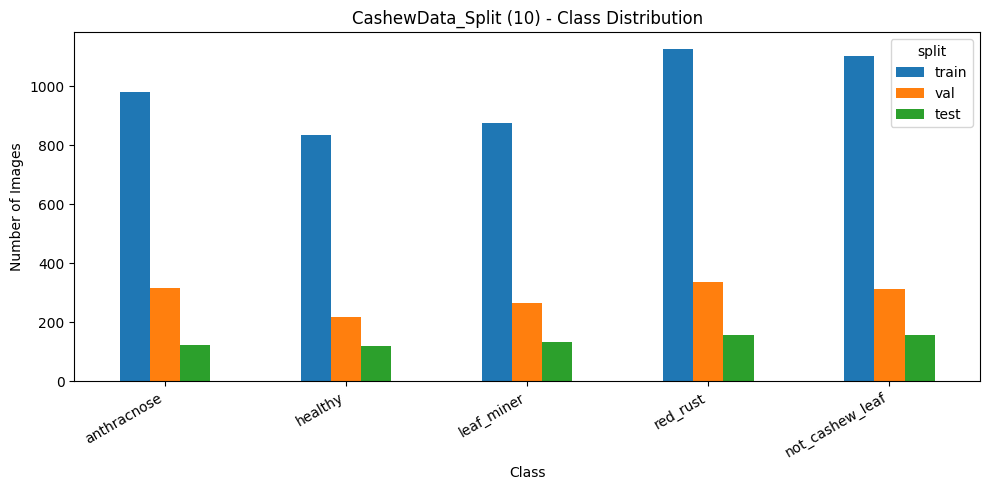

In [9]:

# ============================================================
# 07. DATASET DISTRIBUTION
# ============================================================

ax = stats_df[["train", "val", "test"]].plot(
    kind="bar",
    figsize=(10, 5)
)

ax.set_title("CashewData_Split (10) - Class Distribution")
ax.set_xlabel("Class")
ax.set_ylabel("Number of Images")

plt.xticks(rotation=30, ha="right")
plt.tight_layout()

plt.savefig(
    AGGREGATE_DIR / "class_distribution.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


In [10]:

# ============================================================
# 08. FIXED FILE LISTS + TF.DATA
# ============================================================

CLASS_NAMES = EXPECTED_CLASSES
NUM_CLASSES = len(CLASS_NAMES)
AUTOTUNE = tf.data.AUTOTUNE


def split_arrays(split_name):
    df = (
        valid_df[valid_df["split"] == split_name]
        .copy()
        .reset_index(drop=True)
    )

    return (
        df["path"].to_numpy(),
        df["label"].to_numpy(dtype=np.int32),
        df
    )


train_paths, train_labels, train_meta = split_arrays("train")
val_paths, val_labels, val_meta = split_arrays("val")
test_paths, test_labels, test_meta = split_arrays("test")


def decode_image(path, label):
    image_bytes = tf.io.read_file(path)

    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        [IMG_SIZE, IMG_SIZE],
        method="bilinear"
    )

    return tf.cast(image, tf.float32), label


def make_dataset(paths, labels, seed, training=False):
    ds = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:
        ds = ds.shuffle(
            buffer_size=len(paths),
            seed=seed,
            reshuffle_each_iteration=True
        )

    ds = ds.map(
        decode_image,
        num_parallel_calls=AUTOTUNE
    )

    ds = ds.batch(
        BATCH_SIZE,
        drop_remainder=False
    )

    ds = ds.prefetch(AUTOTUNE)

    return ds


print("Fixed split:")
print("Train :", len(train_paths))
print("Val   :", len(val_paths))
print("Test  :", len(test_paths))

print("\nClass mapping:")
for idx, class_name in enumerate(CLASS_NAMES):
    print(f"{idx}: {class_name}")


Fixed split:
Train : 4920
Val   : 1445
Test  : 686

Class mapping:
0: anthracnose
1: healthy
2: leaf_miner
3: red_rust
4: not_cashew_leaf


## Model and smoke checks

Raw RGB pixels (0–255) enter the model. Augmentation happens only during
training. Internal ImageNet normalization matches EXP-013 and is checked
against Keras DenseNet preprocessing before training. The smoke check uses
one Train batch and one Validation batch; it never reads Test or holdout.


In [11]:
# 08. ImageNet backbone, frozen BN, and smoke test
import tempfile
from PIL import ImageOps

AUGMENTATION_CONFIG = {"horizontal_flip": True, "rotation_factor": 0.08,
                       "zoom_factor": 0.10, "contrast_factor": 0.10,
                       "brightness": False}

def densenet_preprocessing(inputs):
    x = layers.Rescaling(1.0 / 255.0, name="densenet_rescale")(inputs)
    return layers.Normalization(mean=[0.485, 0.456, 0.406],
                                variance=[0.229**2, 0.224**2, 0.225**2],
                                axis=-1, name="densenet_preprocess")(x)

def build_transfer_model(seed, weights="imagenet"):
    set_global_seed(seed)
    inputs = keras.Input((IMG_SIZE, IMG_SIZE, 3), name="raw_rgb")
    augmented = keras.Sequential([
        layers.RandomFlip("horizontal", seed=seed),
        layers.RandomRotation(0.08, seed=seed),
        layers.RandomZoom(0.10, seed=seed),
        layers.RandomContrast(0.10, seed=seed),
    ], name=f"train_only_augmentation_seed_{seed}")(inputs)
    x = densenet_preprocessing(augmented)
    backbone = keras.applications.DenseNet121(include_top=False, weights=weights,
                                               input_shape=(IMG_SIZE, IMG_SIZE, 3), pooling="avg")
    backbone.trainable = False
    features = backbone(x, training=False)  # Keep BN moving statistics fixed in both stages.
    x = layers.Dropout(HEAD_DROPOUT, seed=seed)(features)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax", dtype="float32",
                           name="disease_output")(x)
    return keras.Model(inputs, outputs, name=f"DenseNet121_Transfer_seed_{seed}"), backbone

def set_backbone_stage(backbone, stage):
    if stage == "stage1":
        backbone.trainable = False
    elif stage == "stage2":
        backbone.trainable = True
        for layer in backbone.layers:
            layer.trainable = (layer.name.startswith("conv5_") and
                               not isinstance(layer, layers.BatchNormalization))
        if not any(layer.trainable and layer.weights for layer in backbone.layers):
            raise RuntimeError("No weighted conv5_* layer was unfrozen")
        if any(layer.trainable for layer in backbone.layers
               if isinstance(layer, layers.BatchNormalization)):
            raise RuntimeError("A backbone BatchNorm layer is trainable")
    else:
        raise ValueError(stage)
    return int(sum(np.prod(v.shape) for v in backbone.trainable_weights))

def compile_stage(model, lr):
    model.compile(optimizer=keras.optimizers.AdamW(learning_rate=lr,
                                                  weight_decay=WEIGHT_DECAY),
                  loss=keras.losses.SparseCategoricalCrossentropy(),
                  metrics=["accuracy"], steps_per_execution=1, jit_compile=False)

def save_json(path, value):
    path.write_text(json.dumps(value, indent=2, ensure_ascii=False), encoding="utf-8")

def file_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1 << 20), b""):
            digest.update(block)
    return digest.hexdigest()

if RUN_PIPELINE_SMOKE:
    # enable_op_determinism() requires a global seed before any random op.
    set_global_seed(SEEDS[0])
    parity_input = tf.random.uniform((2, IMG_SIZE, IMG_SIZE, 3), 0, 255, dtype=tf.float32)
    parity_model = keras.Model((p := keras.Input((IMG_SIZE, IMG_SIZE, 3))),
                               densenet_preprocessing(p))
    parity_error = float(tf.reduce_max(tf.abs(
        parity_model(parity_input) - keras.applications.densenet.preprocess_input(parity_input)
    )).numpy())
    if parity_error >= 1e-5:
        raise AssertionError(f"DenseNet preprocessing parity failed: {parity_error}")
    smoke_train = next(iter(make_dataset(train_paths, train_labels, SEEDS[0], training=True)))
    smoke_val = next(iter(make_dataset(val_paths, val_labels, SEEDS[0], training=False)))
    model, backbone = build_transfer_model(SEEDS[0], weights="imagenet")
    initial_backbone = [w.numpy().copy() for w in backbone.weights[:2]]
    stage1_params = set_backbone_stage(backbone, "stage1")
    if stage1_params != 0 or not model.trainable_weights:
        raise AssertionError("Stage 1 trainability is wrong")
    compile_stage(model, STAGE1_LR)
    model.train_on_batch(*smoke_train)
    if any(not np.array_equal(a, w.numpy()) for a, w in zip(initial_backbone, backbone.weights[:2])):
        raise AssertionError("Frozen backbone changed in Stage 1")
    stage1_prob = model(smoke_val[0][:2], training=False).numpy()
    if stage1_prob.shape != (2, NUM_CLASSES) or not np.isfinite(stage1_prob).all():
        raise AssertionError("Invalid model output")
    if not np.allclose(stage1_prob,
                       model(smoke_val[0][:2], training=False).numpy(), atol=1e-6):
        raise AssertionError("Validation/inference path is stochastic")
    if not np.allclose(stage1_prob.sum(axis=1), 1.0, atol=1e-5):
        raise AssertionError("Softmax probabilities do not sum to one")
    bn_layers = [layer for layer in backbone.layers if isinstance(layer, layers.BatchNormalization)]
    bn_means = [layer.moving_mean.numpy().copy() for layer in bn_layers]
    stage2_params = set_backbone_stage(backbone, "stage2")
    if stage2_params <= 0 or stage2_params >= backbone.count_params():
        raise AssertionError("Stage 2 trainable parameter count is implausible")
    old_optimizer = model.optimizer
    compile_stage(model, STAGE2_LR)
    if model.optimizer is old_optimizer:
        raise AssertionError("Stage 2 reused the Stage 1 optimizer")
    model.train_on_batch(*smoke_train)
    if any(not np.array_equal(before, layer.moving_mean.numpy())
           for before, layer in zip(bn_means, bn_layers)):
        raise AssertionError("Backbone BatchNorm moving means changed")
    with tempfile.TemporaryDirectory() as temporary:
        weights_path = Path(temporary) / "smoke.weights.h5"
        model_path = Path(temporary) / "smoke.keras"
        expected = model(smoke_val[0][:2], training=False).numpy()
        model.save_weights(weights_path)
        model.save(model_path)
        head_bias = model.layers[-1].bias
        head_bias.assign_add(tf.one_hot(0, NUM_CLASSES, on_value=20.0,
                                        off_value=0.0, dtype=head_bias.dtype))
        if np.allclose(expected, model(smoke_val[0][:2], training=False).numpy(), atol=1e-5):
            raise AssertionError("Smoke mutation did not change predictions")
        model.load_weights(weights_path)
        if not np.allclose(expected, model(smoke_val[0][:2], training=False).numpy(), atol=1e-5):
            raise AssertionError("Saved weights did not restore predictions")
        restored = keras.models.load_model(model_path, compile=False)
        if not np.allclose(expected, restored(smoke_val[0][:2], training=False).numpy(), atol=1e-5):
            raise AssertionError("Saved .keras model changed predictions")
    save_json(OUT_DIR / "pipeline_smoke.json", {
        "status": "PASS", "preprocess_max_abs_error": parity_error,
        "stage1_backbone_trainable_params": stage1_params,
        "stage2_backbone_trainable_params": stage2_params,
        "backbone_batchnorm_layers": len(bn_layers),
        "weights_and_model_reload": "PASS", "imagenet_initialization": "PASS",
    })
    print("Pipeline smoke PASS: ImageNet, preprocessing, trainability, BN, reload")
    del model, backbone, restored
    keras.backend.clear_session(); gc.collect()
else:
    print("Pipeline smoke NOT_EXECUTED")


Global seed set to: 42
Global seed set to: 42
29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Pipeline smoke PASS: ImageNet, preprocessing, trainability, BN, reload


## Freeze the recipe, then train both stages

The configuration and dataset fingerprint are written before fitting. Each
seed has separate Stage 1 and Stage 2 histories and checkpoints. Stage 2
starts from the best Stage 1 weights, uses a fresh optimizer, and keeps
BatchNorm frozen. The selected seed checkpoint comes from Validation only.


In [12]:
# 09. Immutable experiment recipe
experiment_config = {
    "experiment_id": EXPERIMENT_ID, "notebook_version": NOTEBOOK_VERSION,
    "baseline_source": "EXP-018 protocol; no checkpoints or prior metrics reused",
    "comparison_scope": "new V10 dataset; compare only with runs sharing the exact manifest",
    "dataset": {"name": DATASET_VERSION, "archive": DATASET_ARCHIVE_NAME,
                "archive_sha256": DATASET_ZIP_SHA256,
                "manifest_sha256": DATASET_MANIFEST_SHA256,
                "counts": EXPECTED_TOTALS, "class_names": EXPECTED_CLASSES,
                "real_filename_counts": EXPECTED_REAL_FILENAME_COUNTS},
    "seeds": SEEDS, "input": "raw RGB float32 0..255, bilinear resize 224x224",
    "model": {"backbone": "DenseNet121", "weights": "imagenet",
              "include_top": False, "pooling": "avg", "head_dropout": HEAD_DROPOUT,
              "preprocessing": "inside model: /255 then ImageNet mean/std",
              "augmentation": AUGMENTATION_CONFIG,
              "backbone_call": "backbone(x, training=False)"},
    "optimizer": "AdamW", "weight_decay": WEIGHT_DECAY, "batch_size": BATCH_SIZE,
    "loss": "SparseCategoricalCrossentropy",
    "stage1": {"lr": STAGE1_LR, "max_epochs": STAGE1_EPOCHS,
               "early_patience": STAGE1_EARLY_PATIENCE,
               "reduce_patience": STAGE1_REDUCE_PATIENCE, "min_lr": STAGE1_MIN_LR,
               "trainable_backbone": "none"},
    "stage2": {"lr": STAGE2_LR, "max_epochs": STAGE2_EPOCHS,
               "early_patience": STAGE2_EARLY_PATIENCE,
               "reduce_patience": STAGE2_REDUCE_PATIENCE, "min_lr": STAGE2_MIN_LR,
               "trainable_backbone": "conv5_* non-BatchNorm only"},
    "selection_rule": "lowest Validation loss, higher Validation macro-F1, Stage 1 on tie",
    "deployment_rule": "lowest Validation loss, higher macro-F1, lower seed on tie",
    "test_protocol": "run once after five-seed Validation selection lock in the same execution",
    "holdout_protocol": "120-image four-class Holdout (4); Validation lock precedes evaluation",
}
config_path = OUT_DIR / "experiment_config.json"
if RUN_FULL_TRAINING:
    smoke_path = OUT_DIR / "pipeline_smoke.json"
    if not smoke_path.is_file() or json.loads(smoke_path.read_text(
            encoding="utf-8")).get("status") != "PASS":
        raise RuntimeError("Pipeline smoke must PASS before five-seed training")
if config_path.exists():
    if json.loads(config_path.read_text(encoding="utf-8")) != experiment_config:
        raise ValueError("Existing EXP-022 recipe differs. Use a new experiment ID for changes.")
else:
    save_json(config_path, experiment_config)
CONFIG_SHA256 = file_sha256(config_path)
print("Frozen recipe SHA256:", CONFIG_SHA256)


Frozen recipe SHA256: d9685e5e04456f8cd2318eac3f64fea1b0e8e5a83c389c84fd0a4c0b8fb6fd79


In [13]:
# 10–14. Two-stage five-seed training and Validation-only selection
class EpochAudit(tf.keras.callbacks.Callback):
    def __init__(self):
        super().__init__()
        self.rows = []
        self.current_lr = None
    def on_epoch_begin(self, epoch, logs=None):
        self.current_lr = float(self.model.optimizer.learning_rate.numpy())
    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        self.rows.append({"epoch": epoch + 1, "accuracy": float(logs["accuracy"]),
                          "loss": float(logs["loss"]),
                          "val_accuracy": float(logs["val_accuracy"]),
                          "val_loss": float(logs["val_loss"]),
                          "learning_rate": self.current_lr})

def stage_callbacks(stage_dir, early_patience, reduce_patience, min_lr):
    audit = EpochAudit()
    checkpoint = stage_dir / "best.weights.h5"
    callbacks = [
        audit,
        keras.callbacks.ModelCheckpoint(str(checkpoint), monitor="val_loss", mode="min",
                                        save_best_only=True, save_weights_only=True, verbose=1),
        keras.callbacks.EarlyStopping(monitor="val_loss", mode="min", patience=early_patience,
                                      restore_best_weights=False, verbose=1),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", mode="min", factor=LR_REDUCTION_FACTOR,
                                          patience=reduce_patience, min_lr=min_lr, verbose=1),
        keras.callbacks.CSVLogger(str(stage_dir / "training_log.csv")),
        keras.callbacks.TerminateOnNaN(),
    ]
    return audit, callbacks, checkpoint

def evaluate_candidate(model, val_ds, stage_dir, stage, audit, elapsed, trainable_params):
    history = pd.DataFrame(audit.rows)
    if history.empty or not np.isfinite(history[["loss", "val_loss"]].to_numpy()).all():
        raise RuntimeError(f"Invalid {stage} history")
    history.to_csv(stage_dir / "history.csv", index=False)
    best = history.sort_values(["val_loss", "epoch"], ascending=[True, True]).iloc[0]
    checkpoint = stage_dir / "best.weights.h5"
    if not checkpoint.is_file():
        raise FileNotFoundError(checkpoint)
    model.load_weights(checkpoint)
    val_loss, val_accuracy = model.evaluate(val_ds, verbose=0)
    probabilities = np.asarray(model.predict(val_ds, verbose=0))
    predicted = probabilities.argmax(axis=1)
    candidate = {
        "stage": stage, "best_epoch": int(best["epoch"]),
        "actual_epochs": len(history), "fit_seconds": float(elapsed),
        "val_loss": float(val_loss), "val_accuracy": float(val_accuracy),
        "val_macro_f1": float(f1_score(val_labels, predicted, labels=np.arange(NUM_CLASSES),
                                        average="macro", zero_division=0)),
        "checkpoint_path": str(checkpoint), "checkpoint_sha256": file_sha256(checkpoint),
        "checkpoint_size_mb": checkpoint.stat().st_size / (1024 ** 2),
        "backbone_trainable_params": trainable_params,
        "learning_rate_first": float(history.iloc[0]["learning_rate"]),
        "learning_rate_last": float(history.iloc[-1]["learning_rate"]),
    }
    if not np.isclose(candidate["val_loss"], float(best["val_loss"]), atol=1e-5):
        raise RuntimeError(f"Reloaded {stage} checkpoint differs from best val_loss epoch")
    save_json(stage_dir / "summary.json", candidate)
    return candidate

def save_selected_validation(seed, model, val_ds, seed_dir, selected):
    output = seed_dir / "validation"
    output.mkdir(exist_ok=True)
    _ = model.predict(val_ds.take(1), verbose=0)  # Warm up model tracing.
    prediction_started = time.perf_counter()
    probabilities = np.asarray(model.predict(val_ds, verbose=0))
    prediction_seconds = time.perf_counter() - prediction_started
    y_true = np.asarray(val_labels, dtype=np.int32)
    y_pred = probabilities.argmax(axis=1)
    if probabilities.shape != (len(y_true), NUM_CLASSES):
        raise ValueError("Validation predictions are not aligned to the fixed file list")
    metrics = {
        "seed": seed, "selected_stage": selected["stage"],
        "selected_epoch": selected["best_epoch"],
        "val_loss": selected["val_loss"],
        "val_accuracy": float(accuracy_score(y_true, y_pred)),
        "val_macro_precision": float(precision_score(y_true, y_pred, average="macro", zero_division=0)),
        "val_macro_recall": float(recall_score(y_true, y_pred, average="macro", zero_division=0)),
        "val_macro_f1": float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
        "val_balanced_accuracy": float(balanced_accuracy_score(y_true, y_pred)),
        "prediction_seconds_including_input_pipeline": float(prediction_seconds),
        "inference_time_ms_per_image": float(1000 * prediction_seconds / len(y_true)),
        "anthracnose_recall": float(recall_score(y_true == CLASS_NAMES.index("anthracnose"),
                                                  y_pred == CLASS_NAMES.index("anthracnose"), zero_division=0)),
        "leaf_miner_recall": float(recall_score(y_true == CLASS_NAMES.index("leaf_miner"),
                                                 y_pred == CLASS_NAMES.index("leaf_miner"), zero_division=0)),
    }
    disease_ids = [CLASS_NAMES.index(name) for name in ("anthracnose", "leaf_miner", "red_rust")]
    disease_mask = np.isin(y_true, disease_ids)
    false_healthy_count = int(np.sum(disease_mask & (y_pred == CLASS_NAMES.index("healthy"))))
    metrics.update(false_healthy_count=false_healthy_count,
                   disease_count=int(disease_mask.sum()),
                   false_healthy_rate=float(false_healthy_count / disease_mask.sum()))
    save_json(output / "metrics.json", metrics)
    pd.DataFrame(classification_report(y_true, y_pred, labels=np.arange(NUM_CLASSES),
                                       target_names=CLASS_NAMES, output_dict=True,
                                       zero_division=0)).T.to_csv(output / "classification_report.csv")
    cm = confusion_matrix(y_true, y_pred, labels=np.arange(NUM_CLASSES))
    cm_norm = confusion_matrix(y_true, y_pred, labels=np.arange(NUM_CLASSES), normalize="true")
    for matrix, suffix in ((cm, ""), (cm_norm, "_normalized")):
        pd.DataFrame(matrix, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(
            output / f"confusion_matrix{suffix}.csv")
        fig, ax = plt.subplots(figsize=(8, 7), facecolor="white")
        ax.imshow(matrix, cmap=MATRIX_CMAP, vmin=0,
                  vmax=1 if suffix else max(1, matrix.max()))
        ax.set_xticks(range(NUM_CLASSES), CLASS_NAMES, rotation=40, ha="right")
        ax.set_yticks(range(NUM_CLASSES), CLASS_NAMES)
        for row in range(NUM_CLASSES):
            for column in range(NUM_CLASSES):
                ax.text(column, row, f"{matrix[row, column]:.2f}" if suffix else str(int(matrix[row, column])),
                        ha="center", va="center", color="black")
        ax.set_xlabel("Predicted"); ax.set_ylabel("True")
        fig.tight_layout(); fig.savefig(output / f"confusion_matrix{suffix}.png", dpi=180)
        plt.close(fig)
    predictions = pd.DataFrame({
        "filename": val_meta["path"], "is_real_filename": val_meta["is_real_filename"],
        "true_label": [CLASS_NAMES[i] for i in y_true],
        "predicted_label": [CLASS_NAMES[i] for i in y_pred],
        "confidence": probabilities.max(axis=1), "correct": y_true == y_pred,
    })
    for index, name in enumerate(CLASS_NAMES):
        predictions[f"prob_{name}"] = probabilities[:, index]
    predictions.to_csv(output / "predictions.csv", index=False)
    predictions[~predictions["correct"]].to_csv(output / "error_cases.csv", index=False)
    return metrics

training_rows, validation_rows = [], []
for run_index, seed in enumerate(SEEDS if RUN_FULL_TRAINING else [], start=1):
    seed_dir = OUT_DIR / f"seed_{seed}"
    stage1_dir, stage2_dir = seed_dir / "stage1", seed_dir / "stage2"
    selected_path = seed_dir / "best.weights.h5"
    summary_path = seed_dir / "training_summary.json"
    validation_path = seed_dir / "validation" / "metrics.json"
    if all(path.is_file() for path in (selected_path, summary_path, validation_path,
                                        stage1_dir / "best.weights.h5", stage2_dir / "best.weights.h5")):
        training_rows.append(json.loads(summary_path.read_text(encoding="utf-8")))
        validation_rows.append(json.loads(validation_path.read_text(encoding="utf-8")))
        print("Reusing completed seed", seed)
        continue
    if seed_dir.exists() and any(seed_dir.rglob("*")):
        raise FileExistsError(f"Partial seed output needs review: {seed_dir}")
    for directory in (stage1_dir, stage2_dir):
        directory.mkdir(parents=True)
    print(f"SEED {run_index}/{len(SEEDS)}: {seed}")
    keras.backend.clear_session(); gc.collect(); set_global_seed(seed)
    train_ds = make_dataset(train_paths, train_labels, seed, training=True)
    val_ds = make_dataset(val_paths, val_labels, seed, training=False)
    model, backbone = build_transfer_model(seed, weights="imagenet")

    stage1_params = set_backbone_stage(backbone, "stage1")
    compile_stage(model, STAGE1_LR)
    audit1, callbacks1, _ = stage_callbacks(stage1_dir, STAGE1_EARLY_PATIENCE,
                                            STAGE1_REDUCE_PATIENCE, STAGE1_MIN_LR)
    started = time.perf_counter()
    model.fit(train_ds, validation_data=val_ds, epochs=STAGE1_EPOCHS,
              callbacks=callbacks1, verbose=1)
    stage1_seconds = time.perf_counter() - started
    stage1 = evaluate_candidate(model, val_ds, stage1_dir, "stage1", audit1,
                                stage1_seconds, stage1_params)

    # evaluate_candidate restored Stage 1 best. Stage 2 starts from these exact weights.
    stage2_params = set_backbone_stage(backbone, "stage2")
    old_optimizer = model.optimizer
    compile_stage(model, STAGE2_LR)
    if model.optimizer is old_optimizer:
        raise AssertionError("Stage 2 must have a new optimizer")
    audit2, callbacks2, _ = stage_callbacks(stage2_dir, STAGE2_EARLY_PATIENCE,
                                            STAGE2_REDUCE_PATIENCE, STAGE2_MIN_LR)
    started = time.perf_counter()
    model.fit(train_ds, validation_data=val_ds, epochs=STAGE2_EPOCHS,
              callbacks=callbacks2, verbose=1)
    stage2_seconds = time.perf_counter() - started
    stage2 = evaluate_candidate(model, val_ds, stage2_dir, "stage2", audit2,
                                stage2_seconds, stage2_params)

    selected = min((stage1, stage2),
                   key=lambda row: (row["val_loss"], -row["val_macro_f1"],
                                    0 if row["stage"] == "stage1" else 1))
    set_backbone_stage(backbone, selected["stage"])
    source_checkpoint = stage1_dir if selected["stage"] == "stage1" else stage2_dir
    model.load_weights(source_checkpoint / "best.weights.h5")
    selected_reloaded_loss = float(model.evaluate(val_ds, verbose=0)[0])
    if not np.isclose(selected_reloaded_loss, selected["val_loss"], atol=1e-5):
        raise RuntimeError("Selected stage checkpoint failed reload parity")
    shutil.copyfile(source_checkpoint / "best.weights.h5", selected_path)
    stage_selection = {
        "seed": seed, "selected_stage": selected["stage"],
        "selected_epoch": selected["best_epoch"], "selection_metric": "val_loss",
        "val_loss": selected["val_loss"], "val_macro_f1": selected["val_macro_f1"],
        "tie_break": "higher val_macro_f1, then Stage 1",
        "checkpoint_sha256": file_sha256(selected_path),
        "model_params": int(model.count_params()),
        "stage_candidates": {"stage1": stage1, "stage2": stage2},
    }
    save_json(seed_dir / "stage_selection.json", stage_selection)
    validation = save_selected_validation(seed, model, val_ds, seed_dir, selected)
    summary = {
        "seed": seed, "selected_stage": selected["stage"],
        "stage1_epochs": stage1["actual_epochs"], "stage2_epochs": stage2["actual_epochs"],
        "stage1_training_seconds": stage1_seconds, "stage2_training_seconds": stage2_seconds,
        "training_time_seconds": stage1_seconds + stage2_seconds,
        "stage1_backbone_trainable_params": stage1_params,
        "stage2_backbone_trainable_params": stage2_params,
        "total_parameters": int(model.count_params()),
        "selected_checkpoint_sha256": stage_selection["checkpoint_sha256"],
        "selected_checkpoint_size_mb": selected_path.stat().st_size / (1024 ** 2),
    }
    save_json(summary_path, summary)
    training_rows.append(summary); validation_rows.append(validation)
    del model, backbone, train_ds, val_ds
    keras.backend.clear_session(); gc.collect()

if RUN_FULL_TRAINING:
    training_summary_df = pd.DataFrame(training_rows)
    validation_results_df = pd.DataFrame(validation_rows)
    if training_summary_df["seed"].tolist() != SEEDS or validation_results_df["seed"].tolist() != SEEDS:
        raise RuntimeError("All five seeds must complete before aggregation")
    training_summary_df.to_csv(AGGREGATE_DIR / "training_summary_5seeds.csv", index=False)
    validation_results_df.to_csv(AGGREGATE_DIR / "validation_results_5seeds.csv", index=False)
else:
    training_summary_df = pd.read_csv(AGGREGATE_DIR / "training_summary_5seeds.csv")
    validation_results_df = pd.read_csv(AGGREGATE_DIR / "validation_results_5seeds.csv")
    if training_summary_df["seed"].tolist() != SEEDS or validation_results_df["seed"].tolist() != SEEDS:
        raise ValueError("Saved five-seed order does not match the protocol")

ranked = validation_results_df.sort_values(["val_loss", "val_macro_f1", "seed"],
                                            ascending=[True, False, True])
deployment_seed = int(ranked.iloc[0]["seed"])
selection_lock = {
    "experiment_id": EXPERIMENT_ID, "config_sha256": CONFIG_SHA256,
    "dataset_sha256": DATASET_ZIP_SHA256,
    "dataset_manifest_sha256": DATASET_MANIFEST_SHA256,
    "class_names": CLASS_NAMES, "seeds": SEEDS,
    "selection_rule": experiment_config["selection_rule"],
    "deployment_rule": experiment_config["deployment_rule"],
    "deployment_seed": deployment_seed,
    "validation_sha256": file_sha256(AGGREGATE_DIR / "validation_results_5seeds.csv"),
    "selected_checkpoint_sha256": {
        str(seed): file_sha256(OUT_DIR / f"seed_{seed}" / "best.weights.h5") for seed in SEEDS
    },
}
lock_path = OUT_DIR / "validation_selection_lock.json"
if lock_path.exists():
    previous_lock = json.loads(lock_path.read_text(encoding="utf-8"))
    selection_lock["locked_at"] = previous_lock.get("locked_at")
    if previous_lock != selection_lock:
        raise ValueError("Validation lock changed; do not run Test or holdout")
else:
    selection_lock["locked_at"] = datetime.now().astimezone().isoformat()
    save_json(lock_path, selection_lock)
print("Validation-only deployment seed:", deployment_seed)


SEED 1/5: 42
Global seed set to: 42
Global seed set to: 42
Epoch 1/12
306/308 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.3596 - loss: 1.6543
Epoch 1: val_loss improved from None to 0.65813, saving model to /content/drive/MyDrive/Cashew_Leaf_model_result/training_results/current_dataset/EXP-DENSENET121-TRANSFER-5SEEDS-022/seed_42/stage1/best.weights.h5

Epoch 1: finished saving model to /content/drive/MyDrive/Cashew_Leaf_model_result/training_results/current_dataset/EXP-DENSENET121-TRANSFER-5SEEDS-022/seed_42/stage1/best.weights.h5
308/308 ━━━━━━━━━━━━━━━━━━━━ 11s 20ms/step - accuracy: 0.4894 - loss: 1.2965 - val_accuracy: 0.8083 - val_loss: 0.6581 - learning_rate: 3.0000e-04
Epoch 2/12
305/308 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.7157 - loss: 0.7737
Epoch 2: val_loss improved from 0.65813 to 0.41063, saving model to /content/drive/MyDrive/Cashew_Leaf_model_result/training_results/current_dataset/EXP-DENSENET121-TRANSFER-5SEEDS-022/seed_42/stage1/best.weights.h5

Epoch 2

In [14]:
# 15–17. Validation tables, real_ subgroup, and five-seed panels
summary_columns = ["val_accuracy", "val_macro_precision", "val_macro_recall",
                   "val_macro_f1", "val_balanced_accuracy", "anthracnose_recall",
                   "leaf_miner_recall", "false_healthy_rate"]
summary_rows = []
for metric in summary_columns:
    values = validation_results_df[metric].astype(float)
    summary_rows.append({"metric": metric, "mean": values.mean(),
                         "std": values.std(ddof=1),
                         "report": f"{100*values.mean():.2f} ± {100*values.std(ddof=1):.2f}%"})
inference_ms = validation_results_df["inference_time_ms_per_image"].astype(float)
summary_rows.append({"metric": "inference_time_ms_per_image",
                     "mean": inference_ms.mean(), "std": inference_ms.std(ddof=1),
                     "report": f"{inference_ms.mean():.2f} ± {inference_ms.std(ddof=1):.2f} ms"})
pd.DataFrame(summary_rows).to_csv(AGGREGATE_DIR / "validation_mean_std_summary.csv", index=False)
training_time_columns = ["stage1_training_seconds", "stage2_training_seconds", "training_time_seconds"]
pd.DataFrame([{"metric": column,
               "mean_seconds": training_summary_df[column].mean(),
               "std_seconds": training_summary_df[column].std(ddof=1),
               "total_seconds": training_summary_df[column].sum()}
              for column in training_time_columns]).to_csv(
    AGGREGATE_DIR / "training_time_mean_std_summary.csv", index=False)

real_rows, per_class_rows = [], []
for seed in SEEDS:
    val_dir = OUT_DIR / f"seed_{seed}" / "validation"
    predictions = pd.read_csv(val_dir / "predictions.csv")
    if len(predictions) != len(val_labels):
        raise RuntimeError(f"Seed {seed} Validation rows changed")
    for group, group_df in (("real_filename", predictions[predictions["is_real_filename"]]),
                            ("other_filename", predictions[~predictions["is_real_filename"]])):
        real_rows.append({"seed": seed, "group": group, "correct": int(group_df["correct"].sum()),
                          "total": len(group_df),
                          "accuracy": float(group_df["correct"].mean())})
    report = pd.read_csv(val_dir / "classification_report.csv", index_col=0)
    for class_name in CLASS_NAMES:
        per_class_rows.append({"seed": seed, "class": class_name,
                               "precision": report.loc[class_name, "precision"],
                               "recall": report.loc[class_name, "recall"],
                               "f1": report.loc[class_name, "f1-score"],
                               "support": report.loc[class_name, "support"]})
real_validation_df = pd.DataFrame(real_rows)
for seed in SEEDS:
    row = real_validation_df[(real_validation_df["seed"] == seed) &
                             (real_validation_df["group"] == "real_filename")].iloc[0]
    if int(row["total"]) != EXPECTED_REAL_FILENAME_COUNTS["val"]:
        raise ValueError("The 50 real_ Validation filenames changed")
real_validation_df.to_csv(AGGREGATE_DIR / "real_validation_by_seed.csv", index=False)
pd.DataFrame(per_class_rows).to_csv(AGGREGATE_DIR / "per_class_validation_by_seed.csv", index=False)
pd.DataFrame(per_class_rows).groupby("class")[["precision", "recall", "f1"]].agg(
    ["mean", "std"]).to_csv(AGGREGATE_DIR / "per_class_validation_mean_std.csv")

histories = {}
for seed in SEEDS:
    histories[seed] = (
        pd.read_csv(OUT_DIR / f"seed_{seed}" / "stage1" / "history.csv"),
        pd.read_csv(OUT_DIR / f"seed_{seed}" / "stage2" / "history.csv"),
    )
fig, axes = plt.subplots(2, len(SEEDS), figsize=(28, 10), sharey="row")
for column, seed in enumerate(SEEDS):
    stage1, stage2 = histories[seed]
    boundary = len(stage1)
    for row, metric in enumerate(("accuracy", "loss")):
        ax = axes[row, column]
        for stage_df, offset, stage_name in ((stage1, 0, "Stage 1"), (stage2, boundary, "Stage 2")):
            epoch = stage_df["epoch"] + offset
            ax.plot(epoch, stage_df[metric], color="#2563eb", alpha=0.75,
                    label=f"{stage_name} Train" if row == 0 else None)
            ax.plot(epoch, stage_df[f"val_{metric}"], color="#ea580c", alpha=0.9,
                    label=f"{stage_name} Validation" if row == 0 else None)
            lr = stage_df["learning_rate"].to_numpy()
            reduced = np.flatnonzero(lr[1:] < lr[:-1]) + 1
            for index in reduced:
                ax.axvline(float(epoch.iloc[index]), color="#16a34a", alpha=0.35, linestyle=":")
        ax.axvline(boundary + 0.5, color="black", linestyle="--", alpha=0.8)
        ax.set_xlabel("Combined epoch"); ax.grid(alpha=0.25)
        if column == 0:
            ax.set_ylabel(metric.title())
    axes[0, column].set_title(f"Seed {seed}")
axes[0, 0].legend(fontsize=8)
fig.suptitle("Stage boundary: dashed; learning-rate reductions: dotted green")
fig.tight_layout()
fig.savefig(PANEL_DIR / "training_curves_5seeds_panel.png", dpi=190, bbox_inches="tight")
plt.close(fig)

for normalized, suffix in ((False, ""), (True, "_normalized")):
    fig, axes = plt.subplots(1, len(SEEDS), figsize=(28, 5.5), facecolor="white")
    for column, seed in enumerate(SEEDS):
        matrix = pd.read_csv(OUT_DIR / f"seed_{seed}" / "validation" /
                             f"confusion_matrix{suffix}.csv", index_col=0).to_numpy()
        ax = axes[column]
        ax.imshow(matrix, cmap=MATRIX_CMAP, vmin=0,
                  vmax=1 if normalized else max(1, matrix.max()))
        ax.set_title(f"Seed {seed}")
        ax.set_xticks(range(NUM_CLASSES), CLASS_NAMES, rotation=45, ha="right")
        ax.set_yticks(range(NUM_CLASSES))
        ax.set_yticklabels(CLASS_NAMES if column == 0 else [])
        for row in range(NUM_CLASSES):
            for col in range(NUM_CLASSES):
                ax.text(col, row, f"{matrix[row, col]:.2f}" if normalized else str(int(matrix[row, col])),
                        ha="center", va="center", color="black", fontsize=8)
        ax.set_xlabel("Predicted")
    axes[0].set_ylabel("True")
    fig.tight_layout()
    fig.savefig(PANEL_DIR / f"validation_confusion_matrices{suffix}_5seeds_panel.png",
                dpi=190, bbox_inches="tight")
    plt.close(fig)
print("Validation summary:")
display(pd.DataFrame(summary_rows))
print("Validation real_ filename subgroup:")
display(real_validation_df)


Validation summary:


,metric,mean,std,report
0,val_accuracy,0.967197,0.001994,96.72 ± 0.20%
1,val_macro_precision,0.965369,0.002152,96.54 ± 0.22%
2,val_macro_recall,0.966302,0.002357,96.63 ± 0.24%
3,val_macro_f1,0.965787,0.002131,96.58 ± 0.21%
4,val_balanced_accuracy,0.966302,0.002357,96.63 ± 0.24%
5,anthracnose_recall,0.930380,0.011627,93.04 ± 1.16%
6,leaf_miner_recall,0.949242,0.004319,94.92 ± 0.43%
7,false_healthy_rate,0.010929,0.001728,1.09 ± 0.17%
8,inference_time_ms_per_image,0.625693,0.008487,0.63 ± 0.01 ms


Validation real_ filename subgroup:


,seed,group,correct,total,accuracy
0,42,real_filename,41,50,0.820000
1,42,other_filename,1352,1395,0.969176
2,123,real_filename,42,50,0.840000
3,123,other_filename,1355,1395,0.971326
4,2026,real_filename,41,50,0.820000
5,2026,other_filename,1357,1395,0.972760
6,3407,real_filename,43,50,0.860000
7,3407,other_filename,1357,1395,0.972760
8,7777,real_filename,40,50,0.800000
9,7777,other_filename,1360,1395,0.974910


## Final Test after the Validation lock

All five seeds and the Validation selection lock are completed first. This
cell then scores the 686-image internal Test once with the frozen checkpoints.
A completed result is read back on rerun. Test never changes the recipe.


In [15]:
# 18. Guarded Final Test
def assert_selection_lock():
    saved = json.loads((OUT_DIR / "validation_selection_lock.json").read_text(encoding="utf-8"))
    if saved != selection_lock or saved["config_sha256"] != file_sha256(config_path):
        raise ValueError("Frozen Validation/config lock changed")
    for seed in SEEDS:
        actual = file_sha256(OUT_DIR / f"seed_{seed}" / "best.weights.h5")
        if actual != saved["selected_checkpoint_sha256"][str(seed)]:
            raise ValueError(f"Seed {seed} checkpoint changed after Validation lock")
    return saved

def load_selected_model(seed):
    # weights=None is only for reconstructing architecture before immediately
    # restoring the EXP-022 trained checkpoint. Training always uses ImageNet.
    model, backbone = build_transfer_model(seed, weights=None)
    selected = json.loads((OUT_DIR / f"seed_{seed}" / "stage_selection.json").read_text(
        encoding="utf-8"))
    set_backbone_stage(backbone, selected["selected_stage"])
    model.load_weights(OUT_DIR / f"seed_{seed}" / "best.weights.h5")
    return model

if RUN_FINAL_TEST and (AGGREGATE_DIR / "test_results_5seeds.csv").is_file():
    assert_selection_lock()
    test_results_df = pd.read_csv(AGGREGATE_DIR / "test_results_5seeds.csv")
    if test_results_df["seed"].tolist() != SEEDS or any(
            not (OUT_DIR / f"seed_{seed}" / "test" / "predictions.csv").is_file()
            for seed in SEEDS):
        raise RuntimeError("Existing Final Test artifacts are incomplete.")
    print("Final Test already completed; reading frozen results.")
elif RUN_FINAL_TEST:
    assert_selection_lock()
    if any((OUT_DIR / f"seed_{seed}" / "test" / "metrics.json").exists() for seed in SEEDS):
        raise RuntimeError("Partial Test exists; inspect before retrying to avoid re-scoring.")
    test_ds = make_dataset(test_paths, test_labels, SEEDS[0], training=False)
    test_rows = []
    for seed in SEEDS:
        keras.backend.clear_session(); gc.collect()
        model = load_selected_model(seed)
        output = OUT_DIR / f"seed_{seed}" / "test"
        output.mkdir(exist_ok=True)
        _ = model.predict(test_ds.take(1), verbose=0)  # Warm up tracing.
        started = time.perf_counter()
        probability = np.asarray(model.predict(test_ds, verbose=0))
        elapsed = time.perf_counter() - started
        y_true = np.asarray(test_labels, dtype=np.int32)
        y_pred = probability.argmax(axis=1)
        if probability.shape != (len(y_true), NUM_CLASSES):
            raise RuntimeError("Final Test prediction count mismatch")
        test_row = {
            "seed": seed, "images": len(y_true),
            "loss": float(-np.log(np.clip(probability[np.arange(len(y_true)), y_true], 1e-7, 1)).mean()),
            "accuracy": float(accuracy_score(y_true, y_pred)),
            "macro_precision": float(precision_score(y_true, y_pred, average="macro", zero_division=0)),
            "macro_recall": float(recall_score(y_true, y_pred, average="macro", zero_division=0)),
            "macro_f1": float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
            "balanced_accuracy": float(balanced_accuracy_score(y_true, y_pred)),
            "prediction_seconds_including_input_pipeline": elapsed,
            "inference_time_ms_per_image": 1000 * elapsed / len(y_true),
        }
        for group_name, mask in (("real_filename", test_meta["is_real_filename"].to_numpy(dtype=bool)),
                                 ("other_filename", ~test_meta["is_real_filename"].to_numpy(dtype=bool))):
            test_row[f"{group_name}_correct"] = int((y_true[mask] == y_pred[mask]).sum())
            test_row[f"{group_name}_total"] = int(mask.sum())
            test_row[f"{group_name}_accuracy"] = float(accuracy_score(y_true[mask], y_pred[mask]))
        save_json(output / "metrics.json", test_row)
        pd.DataFrame(classification_report(y_true, y_pred, labels=np.arange(NUM_CLASSES),
                                           target_names=CLASS_NAMES, output_dict=True,
                                           zero_division=0)).T.to_csv(output / "classification_report.csv")
        predictions = pd.DataFrame({"filename": test_meta["path"],
                                    "is_real_filename": test_meta["is_real_filename"],
                                    "true_label": [CLASS_NAMES[i] for i in y_true],
                                    "predicted_label": [CLASS_NAMES[i] for i in y_pred],
                                    "confidence": probability.max(axis=1),
                                    "correct": y_true == y_pred})
        for index, name in enumerate(CLASS_NAMES):
            predictions[f"prob_{name}"] = probability[:, index]
        predictions.to_csv(output / "predictions.csv", index=False)
        predictions[~predictions["correct"]].to_csv(output / "error_cases.csv", index=False)
        cm = confusion_matrix(y_true, y_pred, labels=np.arange(NUM_CLASSES))
        for normalized, suffix in ((False, ""), (True, "_normalized")):
            matrix = confusion_matrix(y_true, y_pred, labels=np.arange(NUM_CLASSES),
                                      normalize="true" if normalized else None)
            pd.DataFrame(matrix, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(
                output / f"confusion_matrix{suffix}.csv")
        test_rows.append(test_row)
        del model
    test_results_df = pd.DataFrame(test_rows)
    test_results_df.to_csv(AGGREGATE_DIR / "test_results_5seeds.csv", index=False)
    pd.DataFrame([{"metric": col, "mean": test_results_df[col].mean(),
                   "std": test_results_df[col].std(ddof=1)}
                  for col in ("accuracy", "macro_precision", "macro_recall", "macro_f1",
                              "balanced_accuracy", "inference_time_ms_per_image")]).to_csv(
        AGGREGATE_DIR / "test_mean_std_summary.csv", index=False)
    for normalized, suffix in ((False, ""), (True, "_normalized")):
        fig, axes = plt.subplots(1, len(SEEDS), figsize=(28, 5.5), facecolor="white")
        for column, seed in enumerate(SEEDS):
            matrix = pd.read_csv(OUT_DIR / f"seed_{seed}" / "test" /
                                 f"confusion_matrix{suffix}.csv", index_col=0).to_numpy()
            ax = axes[column]
            ax.imshow(matrix, cmap=MATRIX_CMAP, vmin=0,
                      vmax=1 if normalized else max(1, matrix.max()))
            ax.set_title(f"Seed {seed}")
            ax.set_xticks(range(NUM_CLASSES), CLASS_NAMES, rotation=45, ha="right")
            ax.set_yticks(range(NUM_CLASSES))
            ax.set_yticklabels(CLASS_NAMES if column == 0 else [])
            for row in range(NUM_CLASSES):
                for col in range(NUM_CLASSES):
                    ax.text(col, row, f"{matrix[row, col]:.2f}" if normalized else str(int(matrix[row, col])),
                            ha="center", va="center", color="black", fontsize=8)
            ax.set_xlabel("Predicted")
        axes[0].set_ylabel("True")
        fig.tight_layout()
        fig.savefig(PANEL_DIR / f"test_confusion_matrices{suffix}_5seeds_panel.png",
                    dpi=190, bbox_inches="tight")
        plt.close(fig)
    display(test_results_df)
else:
    print("Final Test PENDING (RUN_FINAL_TEST=False)")


Global seed set to: 42
Global seed set to: 123
Global seed set to: 2026
Global seed set to: 3407
Global seed set to: 7777


,seed,images,loss,accuracy,macro_precision,macro_recall,macro_f1,balanced_accuracy,prediction_seconds_including_input_pipeline,inference_time_ms_per_image,real_filename_correct,real_filename_total,real_filename_accuracy,other_filename_correct,other_filename_total,other_filename_accuracy
0,42,686,0.173586,0.953353,0.950645,0.949790,0.950060,0.949790,1.674458,2.440900,24,28,0.857143,630,658,0.957447
1,123,686,0.172226,0.950437,0.946744,0.946692,0.946696,0.946692,1.667789,2.431179,25,28,0.892857,627,658,0.952888
2,2026,686,0.177848,0.947522,0.943923,0.943303,0.943598,0.943303,1.669314,2.433402,25,28,0.892857,625,658,0.949848
3,3407,686,0.175939,0.944606,0.942830,0.940658,0.940951,0.940658,1.656633,2.414917,23,28,0.821429,625,658,0.949848
4,7777,686,0.175405,0.946064,0.942404,0.942216,0.942161,0.942216,1.651964,2.408111,25,28,0.892857,624,658,0.948328


## External real holdout (4)

The 120-image archive has 46 anthracnose, 13 healthy, 36 leaf miner and
25 red rust images. It is audited for exact byte overlap with every Train,
Validation and Test image in Split (10). All five locked models are scored.
Four-class macro metrics and support are reported separately from Test.


In [16]:
"""External classification evaluation for EXP-022.

This file has no training code. Holdout labels never select checkpoints or seeds.
"""

import hashlib
import json
import os
import stat
import time
import zipfile
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from PIL import Image
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.metrics import f1_score, precision_score, recall_score


REAL_HOLDOUT_HELPER_VERSION = "006.1"
REAL_HOLDOUT_CMAP = LinearSegmentedColormap.from_list(
    "real_holdout_readable_blues", ["#ffffff", "#dbeafe", "#93c5fd"]
)


def holdout_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest().upper()


def resolve_holdout_archive(archive_name, override=None):
    if override is not None:
        candidate = Path(override)
        if not candidate.is_file():
            raise FileNotFoundError(candidate)
        return candidate
    if RUNTIME == "Colab":
        candidate = DRIVE_PROJECT_DIR / "Dataset" / archive_name
        if candidate.is_file():
            return candidate
    if os.name == "nt":
        candidate = Path(r"D:\Study\KhoaLuanTotNghiep\Dataset") / archive_name
        if candidate.is_file():
            return candidate
    if Path("/kaggle/input").is_dir():
        candidates = sorted(Path("/kaggle/input").rglob(archive_name))
        if len(candidates) == 1:
            return candidates[0]
    raise FileNotFoundError(
        f"Cannot uniquely locate {archive_name}. Set REAL_HOLDOUT_ARCHIVE_OVERRIDE "
        "to the mounted ZIP path; on Colab check the project shortcut and original-folder permissions."
    )


def prepare_real_holdout(archive_path, extraction_dir, class_names, expected_sha256,
                         expected_counts, reference_rows, audit_dir):
    """Verify the frozen archive, labels, decoding and byte overlap with Split (10).

    reference_rows: dictionaries with path/split and optional existing sha256.
    Exact-byte checking does not establish independence of near-duplicate photos.
    """
    archive_path, extraction_dir, audit_dir = map(Path, (archive_path, extraction_dir, audit_dir))
    actual_hash = holdout_sha256(archive_path)
    if actual_hash != expected_sha256.upper():
        raise ValueError(f"Holdout archive changed: {actual_hash}; expected {expected_sha256}.")
    marker = extraction_dir / ".archive_sha256"
    if extraction_dir.exists():
        if not marker.is_file() or marker.read_text(encoding="utf-8").strip() != actual_hash:
            raise FileExistsError(f"Unverified extraction: {extraction_dir}; choose a new directory.")
    else:
        with zipfile.ZipFile(archive_path) as archive:
            resolved_root = extraction_dir.resolve()
            for member in archive.infolist():
                target = (extraction_dir / member.filename.replace("\\", "/")).resolve()
                is_symlink = stat.S_ISLNK(member.external_attr >> 16)
                if is_symlink or (target != resolved_root and resolved_root not in target.parents):
                    raise ValueError(f"Unsafe ZIP member: {member.filename}")
            extraction_dir.mkdir(parents=True)
            archive.extractall(extraction_dir)
        marker.write_text(actual_hash, encoding="utf-8")

    dataset_root = extraction_dir / "RL_Cashew_holdout"
    if not dataset_root.is_dir():
        raise FileNotFoundError(dataset_root)
    found_classes = sorted(p.name for p in dataset_root.iterdir() if p.is_dir())
    if found_classes != sorted(expected_counts) or not set(found_classes).issubset(class_names):
        raise ValueError(f"Unexpected holdout class folders: {found_classes}")
    rows = []
    for label, name in enumerate(class_names):
        class_dir = dataset_root / name
        files = sorted(p for p in class_dir.rglob("*") if p.is_file()) if class_dir.is_dir() else []
        if len(files) != expected_counts.get(name, 0):
            raise ValueError(f"Unexpected holdout count for {name}: {len(files)}")
        for image_path in files:
            if image_path.suffix.lower() not in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}:
                raise ValueError(f"Unsupported holdout image: {image_path}")
            with Image.open(image_path) as image:
                image.verify()
            with Image.open(image_path) as image:
                image.convert("RGB").load()
            rows.append({"path": str(image_path), "relative_path": image_path.relative_to(dataset_root).as_posix(),
                         "class": name, "label": label, "sha256": holdout_sha256(image_path)})
    manifest = pd.DataFrame(rows)
    if manifest.empty or manifest["sha256"].duplicated().any():
        raise ValueError("Holdout is empty or contains duplicate image bytes.")
    # A marker alone is insufficient: verify cached extraction bytes against the ZIP.
    with zipfile.ZipFile(archive_path) as frozen_archive:
        for row in rows:
            digest = hashlib.sha256()
            with frozen_archive.open("RL_Cashew_holdout/" + row["relative_path"]) as stream:
                for block in iter(lambda: stream.read(1024 * 1024), b""):
                    digest.update(block)
            if digest.hexdigest().upper() != row["sha256"]:
                raise ValueError(f"Cached holdout extraction changed: {row['relative_path']}")
    audit_dir.mkdir(parents=True, exist_ok=True)
    manifest.to_csv(audit_dir / "archive_dataset_manifest.csv", index=False)

    references = list(reference_rows)
    if not references or not {"train", "val", "test"}.issubset({r["split"] for r in references}):
        raise ValueError("Overlap audit needs the full train/val/test Split (10) reference manifest.")
    holdout_hashes = set(manifest["sha256"])
    holdout_path_by_hash = dict(zip(manifest["sha256"], manifest["relative_path"]))
    overlaps = []
    reference_digest = hashlib.sha256()
    for row in references:
        digest = row.get("sha256") or holdout_sha256(row["path"])
        digest = digest.upper()
        identity = row.get("relative_path", str(row["path"]))
        reference_digest.update(f"{row['split']}\0{identity}\0{digest}\n".encode("utf-8"))
        if digest in holdout_hashes:
            overlaps.append({"reference_path": str(row["path"]), "split": row["split"],
                             "holdout_relative_path": holdout_path_by_hash[digest],
                             "sha256": digest})
    # Exact overlap is unexpected for this frozen V10/holdout04 pair.
    expected_overlap = set()  # Verified against both local ZIPs before authoring EXP-022.
    observed_overlap = {(row["split"], row["holdout_relative_path"]) for row in overlaps}
    if observed_overlap != expected_overlap:
        raise ValueError(f"Unexpected holdout/Split (10) byte overlaps: {overlaps}")
    evaluated_manifest = manifest[~manifest["sha256"].isin(
        {row["sha256"] for row in overlaps}
    )].reset_index(drop=True)
    evaluated_manifest.to_csv(audit_dir / "dataset_manifest.csv", index=False)
    pd.DataFrame(overlaps).to_csv(audit_dir / "excluded_overlap_images.csv", index=False)
    present = [name for name in class_names if expected_counts.get(name, 0) > 0]
    audit = {"archive_sha256": actual_hash, "archive_name": archive_path.name,
             "archive_manifest_sha256": hashlib.sha256(manifest[["relative_path", "class", "label", "sha256"]]
                  .to_csv(index=False).encode()).hexdigest(),
              "manifest_sha256": hashlib.sha256(evaluated_manifest[["relative_path", "class", "label", "sha256"]]
                 .to_csv(index=False).encode()).hexdigest(),
             "counts": {name: expected_counts.get(name, 0) for name in class_names},
             "images": len(evaluated_manifest), "archive_images": len(manifest),
              "excluded_overlap_images": len(overlaps),
              "evaluated_counts": evaluated_manifest["class"].value_counts().to_dict(),
              "present_classes": present,
             "unsupported_classes": [name for name in class_names if name not in present],
             "reference_images_checked": len(references), "reference_fingerprint": reference_digest.hexdigest(),
             "byte_overlap_count": len(overlaps), "byte_overlaps": overlaps,
             "limitation": "Byte audit only; near-duplicate photos and shared trees/sessions need a separate audit."}
    (audit_dir / "dataset_audit.json").write_text(json.dumps(audit, indent=2), encoding="utf-8")
    print("Real holdout:", len(evaluated_manifest), "evaluated of", len(manifest),
          "archive images; excluded exact Test duplicate:", overlaps)
    print("Present classes:", present)
    print("Not evaluated (no true examples):", audit["unsupported_classes"])
    return evaluated_manifest, audit


def save_real_holdout_seed(manifest, probabilities, class_names, output_dir):
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    probabilities = np.asarray(probabilities, dtype=np.float64)
    if probabilities.shape != (len(manifest), len(class_names)) or not np.isfinite(probabilities).all():
        raise ValueError("Holdout predictions have invalid shape or non-finite values.")
    if (probabilities < 0).any() or not np.allclose(probabilities.sum(axis=1), 1, atol=1e-5):
        raise ValueError("Holdout evaluator expects probabilities, not logits.")
    y_true = manifest["label"].to_numpy(dtype=np.int32)
    y_pred = probabilities.argmax(axis=1)
    present_ids = sorted(set(y_true.tolist()))
    all_ids = list(range(len(class_names)))
    result = {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "macro_precision_present_classes": float(precision_score(y_true, y_pred, labels=present_ids, average="macro", zero_division=0)),
        "macro_recall_present_classes": float(recall_score(y_true, y_pred, labels=present_ids, average="macro", zero_division=0)),
        "macro_f1_present_classes": float(f1_score(y_true, y_pred, labels=present_ids, average="macro", zero_division=0)),
        "balanced_accuracy_present_classes": float(recall_score(y_true, y_pred, labels=present_ids, average="macro", zero_division=0)),
        "images": len(manifest), "macro_class_count": len(present_ids),
    }
    report = pd.DataFrame(classification_report(y_true, y_pred, labels=all_ids,
        target_names=class_names, output_dict=True, zero_division=0)).transpose()
    per_class = report.loc[class_names, ["precision", "recall", "f1-score", "support"]].copy()
    per_class["evaluated"] = per_class["support"] > 0
    # No evidence for unsupported true classes: don't present placeholder zeros as performance.
    per_class.loc[~per_class["evaluated"], ["precision", "recall", "f1-score"]] = np.nan
    per_class.to_csv(output_dir / "per_class_metrics.csv", index_label="class")
    readable_report = per_class.copy()
    readable_report["scope"] = np.where(readable_report["evaluated"], "true class present", "not evaluated: zero true support")
    readable_report.loc["macro avg (present classes)"] = [
        result["macro_precision_present_classes"], result["macro_recall_present_classes"],
        result["macro_f1_present_classes"], len(manifest), True,
        f"{len(present_ids)} supported true classes only",
    ]
    readable_report.loc["weighted avg"] = [
        report.loc["weighted avg", "precision"], report.loc["weighted avg", "recall"],
        report.loc["weighted avg", "f1-score"], len(manifest), True, "weighted by true support",
    ]
    readable_report.to_csv(output_dir / "classification_report.csv", index_label="class")
    predictions = manifest[["relative_path", "class", "label"]].copy()
    predictions["predicted_label"] = y_pred
    predictions["predicted_class"] = [class_names[i] for i in y_pred]
    predictions["confidence"] = probabilities.max(axis=1)
    predictions["correct"] = y_true == y_pred
    for label, name in enumerate(class_names):
        predictions[f"probability_{name}"] = probabilities[:, label]
    predictions.to_csv(output_dir / "predictions.csv", index=False)
    matrix = confusion_matrix(y_true, y_pred, labels=all_ids)
    for normalized, suffix in ((False, ""), (True, "_normalized")):
        values = matrix / np.maximum(matrix.sum(axis=1, keepdims=True), 1) if normalized else matrix
        pd.DataFrame(values, index=class_names, columns=class_names).to_csv(output_dir / f"confusion_matrix{suffix}.csv")
        fig, ax = plt.subplots(figsize=(9, 8), facecolor="white")
        ax.set_facecolor("white")
        ax.imshow(values, cmap=REAL_HOLDOUT_CMAP, vmin=0,
                  vmax=1 if normalized else max(int(matrix.max()), 1))
        ax.set_xticks(all_ids, class_names, rotation=40, ha="right", color="black")
        ax.set_yticks(all_ids, class_names, color="black")
        ax.set_xlabel("Predicted class", color="black")
        ax.set_ylabel("True class", color="black")
        ax.set_title("Real holdout" + (" (row normalized)" if normalized else ""), color="black")
        for row in all_ids:
            for col in all_ids:
                text = f"{values[row, col]:.2f}" if normalized else str(int(values[row, col]))
                if normalized and row not in present_ids:
                    text = "N/A"
                ax.text(col, row, text, ha="center", va="center", color="black")
        fig.tight_layout()
        fig.savefig(output_dir / f"confusion_matrix{suffix}.png", dpi=180)
        plt.close(fig)
    (output_dir / "metrics.json").write_text(json.dumps(result, indent=2), encoding="utf-8")
    return result


def evaluate_real_holdout(manifest, audit, class_names, seeds, validation_results,
                          checkpoints, load_model, make_dataset, clear_session,
                          output_dir, outputs_are_logits=False):
    """Freeze all checkpoints and validation selection BEFORE any prediction.

    Completed evaluations are read back, not repeated. Interrupted evaluations
    may resume only with the same checkpoint, validation and archive fingerprints.
    """
    output_dir = Path(output_dir)
    seeds = [int(seed) for seed in seeds]
    validation_results = validation_results.copy()
    if validation_results["seed"].tolist() != seeds:
        raise ValueError("Holdout evaluation requires completed, ordered validation for every seed.")
    if not np.isfinite(validation_results[["val_macro_f1", "val_loss"]].to_numpy()).all():
        raise ValueError("Validation selection metrics are incomplete.")
    ranked = validation_results.sort_values(["val_loss", "val_macro_f1", "seed"], ascending=[True, False, True])
    deployment_seed = int(ranked.iloc[0]["seed"])
    checkpoint_hashes = {str(seed): holdout_sha256(checkpoints[seed]) for seed in seeds}
    lock = {"helper_version": REAL_HOLDOUT_HELPER_VERSION, "archive_sha256": audit["archive_sha256"],
            "manifest_sha256": audit["manifest_sha256"],
            "reference_fingerprint": audit["reference_fingerprint"], "seeds": seeds,
            "checkpoint_sha256": checkpoint_hashes, "deployment_seed": deployment_seed,
            # Canonical float precision avoids false lock changes on CSV reload.
            "validation_sha256": hashlib.sha256(validation_results.to_csv(index=False, float_format="%.12g").encode()).hexdigest(),
            "model_classes": class_names, "macro_classes": audit["present_classes"],
            "selection_source": "validation only; lowest val_loss, then macro F1 and seed",
            "outputs_are_logits": outputs_are_logits}
    lock_path = output_dir / "evaluation_lock.json"
    if lock_path.exists():
        if json.loads(lock_path.read_text(encoding="utf-8")) != lock:
            raise ValueError("Holdout lock changed. Do not retune using holdout or overwrite its results.")
    else:
        output_dir.mkdir(parents=True, exist_ok=True)
        lock_path.write_text(json.dumps(lock, indent=2), encoding="utf-8")
    aggregate_dir = output_dir / "aggregate"
    aggregate_dir.mkdir(exist_ok=True)
    results_path = aggregate_dir / "real_holdout_results_5seeds.csv"
    if (output_dir / "evaluation_completed.json").exists():
        print("Real holdout already completed; reading frozen results, not running predictions again.")
        return pd.read_csv(results_path)
    result_rows = []
    for seed in seeds:
        seed_dir = output_dir / f"seed_{seed}"
        completed_path = seed_dir / "evaluation_completed.json"
        if completed_path.exists():
            row = json.loads(completed_path.read_text(encoding="utf-8"))
        else:
            clear_session()
            model = load_model(seed)
            dataset = make_dataset(manifest)
            _ = model.predict(dataset.take(1), verbose=0)  # Warm up tracing.
            start = time.perf_counter()
            scores = np.asarray(model.predict(dataset, verbose=0))
            prediction_seconds = time.perf_counter() - start
            if outputs_are_logits:
                exponentials = np.exp(scores - scores.max(axis=1, keepdims=True))
                scores = exponentials / exponentials.sum(axis=1, keepdims=True)
            row = {"seed": seed, **save_real_holdout_seed(manifest, scores, class_names, seed_dir),
                   "prediction_seconds_including_input_pipeline": prediction_seconds,
                   "inference_time_ms_per_image": 1000.0 * prediction_seconds / len(manifest),
                   "fps_including_input_pipeline": len(manifest) / prediction_seconds}
            completed_path.write_text(json.dumps(row, indent=2), encoding="utf-8")
            del model, scores, dataset
            clear_session()
        result_rows.append(row)
    results = pd.DataFrame(result_rows)
    results.to_csv(results_path, index=False)
    metric_columns = [c for c in results if c not in {"seed", "images", "macro_class_count"}]
    results[metric_columns].agg(["mean", "std"]).transpose().to_csv(aggregate_dir / "real_holdout_mean_std.csv")
    per_class = pd.concat([pd.read_csv(output_dir / f"seed_{seed}" / "per_class_metrics.csv")
                          .assign(seed=seed) for seed in seeds], ignore_index=True)
    per_class.groupby("class")[["precision", "recall", "f1-score"]].agg(["mean", "std"]).to_csv(
        aggregate_dir / "per_class_real_holdout_mean_std.csv")
    deployment_result = next(row for row in result_rows if row["seed"] == deployment_seed)
    (aggregate_dir / "deployment_seed_result.json").write_text(json.dumps({
        "selection_source": "validation only, fixed before holdout", "result": deployment_result,
    }, indent=2), encoding="utf-8")
    (output_dir / "evaluation_completed.json").write_text(json.dumps({
        "completed_at_utc": datetime.now(timezone.utc).isoformat(),
        "note": "No model or seed selection on holdout. SD measures training-seed variability, not sampling uncertainty.",
    }, indent=2), encoding="utf-8")
    print("Real holdout results (macro metrics over supported true classes only):")
    print(results)
    return results


# 19. Guarded, exposed real-world comparison
if RUN_REAL_HOLDOUT:
    assert_selection_lock()
    holdout_archive = resolve_holdout_archive(REAL_HOLDOUT_ARCHIVE_NAME,
                                               REAL_HOLDOUT_ARCHIVE_OVERRIDE)
    holdout_reference_rows = valid_df.assign(
        relative_path=valid_df["path"].map(
            lambda path: Path(path).relative_to(DATASET_PATH).as_posix())
    ).to_dict("records")
    if Path("/content").is_dir():
        holdout_extract_dir = Path("/content/real_holdout_022") / REAL_HOLDOUT_ARCHIVE_SHA256[:12]
    elif Path("/kaggle/working").is_dir():
        holdout_extract_dir = Path("/kaggle/working/real_holdout_022") / REAL_HOLDOUT_ARCHIVE_SHA256[:12]
    else:
        holdout_extract_dir = Path(tempfile.gettempdir()) / "real_holdout_022" / REAL_HOLDOUT_ARCHIVE_SHA256[:12]
    holdout_dir = OUT_DIR / "real_holdout"
    holdout_manifest, holdout_audit = prepare_real_holdout(
        holdout_archive, holdout_extract_dir, CLASS_NAMES,
        REAL_HOLDOUT_ARCHIVE_SHA256, REAL_HOLDOUT_EXPECTED_COUNTS,
        holdout_reference_rows, holdout_dir,
    )
    if len(holdout_manifest) != 120:
        raise ValueError("Holdout04 must have 120 scored images after exact-overlap audit")
    def make_holdout_dataset(manifest):
        dataset = tf.data.Dataset.from_tensor_slices((
            manifest["path"].tolist(), manifest["label"].to_numpy(dtype=np.int32)))
        return dataset.map(decode_image, num_parallel_calls=tf.data.AUTOTUNE).batch(
            BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
    def clear_holdout_session():
        keras.backend.clear_session(); gc.collect()
    checkpoint_paths = {seed: OUT_DIR / f"seed_{seed}" / "best.weights.h5" for seed in SEEDS}
    holdout_results_df = evaluate_real_holdout(
        holdout_manifest, holdout_audit, CLASS_NAMES, SEEDS, validation_results_df,
        checkpoint_paths, load_selected_model, make_holdout_dataset,
        clear_holdout_session, holdout_dir, outputs_are_logits=False,
    )
    save_json(holdout_dir / "interpretation.json", {
        "status": "EVALUATED_SEPARATELY", "evaluated_images": 120,
        "excluded_exact_test_duplicate": 0,
        "use": "external four-class descriptive evaluation; no Test/holdout tuning",
        "selection_source": "Validation only",
    })
    for normalized, suffix in ((False, ""), (True, "_normalized")):
        fig, axes = plt.subplots(1, len(SEEDS), figsize=(28, 5.5), facecolor="white")
        for column, seed in enumerate(SEEDS):
            matrix = pd.read_csv(holdout_dir / f"seed_{seed}" /
                                 f"confusion_matrix{suffix}.csv", index_col=0).to_numpy()
            ax = axes[column]
            ax.imshow(matrix, cmap=REAL_HOLDOUT_CMAP, vmin=0,
                      vmax=1 if normalized else max(1, matrix.max()))
            ax.set_title(f"Seed {seed}")
            ax.set_xticks(range(NUM_CLASSES), CLASS_NAMES, rotation=45, ha="right")
            ax.set_yticks(range(NUM_CLASSES))
            ax.set_yticklabels(CLASS_NAMES if column == 0 else [])
            for row in range(NUM_CLASSES):
                for col in range(NUM_CLASSES):
                    ax.text(col, row, f"{matrix[row, col]:.2f}" if normalized else str(int(matrix[row, col])),
                            ha="center", va="center", color="black", fontsize=8)
            ax.set_xlabel("Predicted")
        axes[0].set_ylabel("True")
        fig.tight_layout()
        fig.savefig(holdout_dir / f"holdout_confusion_matrices{suffix}_5seeds_panel.png",
                    dpi=190, bbox_inches="tight")
        plt.close(fig)
    display(holdout_results_df)
else:
    print("Real holdout PENDING (RUN_REAL_HOLDOUT=False)")


Real holdout: 120 evaluated of 120 archive images; excluded exact Test duplicate: []
Present classes: ['anthracnose', 'healthy', 'leaf_miner', 'red_rust']
Not evaluated (no true examples): ['not_cashew_leaf']
Global seed set to: 42
Global seed set to: 123
Global seed set to: 2026
Global seed set to: 3407
Global seed set to: 7777
Real holdout results (macro metrics over supported true classes only):
   seed  accuracy  macro_precision_present_classes  \
0    42  0.708333                         0.747113   
1   123  0.708333                         0.741914   
2  2026  0.766667                         0.772413   
3  3407  0.691667                         0.742709   
4  7777  0.733333                         0.757018   

   macro_recall_present_classes  macro_f1_present_classes  \
0                      0.698315                  0.711492   
1                      0.687675                  0.706515   
2                      0.734776                  0.748735   
3                      0.6645

,seed,accuracy,macro_precision_present_classes,macro_recall_present_classes,macro_f1_present_classes,balanced_accuracy_present_classes,images,macro_class_count,prediction_seconds_including_input_pipeline,inference_time_ms_per_image,fps_including_input_pipeline
0,42,0.708333,0.747113,0.698315,0.711492,0.698315,120,4,1.450446,12.087050,82.733174
1,123,0.708333,0.741914,0.687675,0.706515,0.687675,120,4,1.438544,11.987863,83.417701
2,2026,0.766667,0.772413,0.734776,0.748735,0.734776,120,4,1.422601,11.855012,84.352506
3,3407,0.691667,0.742709,0.664555,0.687327,0.664555,120,4,1.446450,12.053751,82.961728
4,7777,0.733333,0.757018,0.742211,0.742743,0.742211,120,4,1.436791,11.973260,83.519443


## Export the selected model and inference adapter

The deployment seed was frozen by Validation before either optional
evaluation. The exported `.keras` model accepts raw RGB pixels and contains
the preprocessing layer. The adapter applies EXIF orientation and bilinear
resize, then sends RGB float32 to the model without another normalization.


In [17]:
# 21. Deployment model, feature models, reusable code
assert_selection_lock()
keras.backend.clear_session(); gc.collect()
deployment_model = load_selected_model(deployment_seed)
deployment_path = MODEL_PACKAGE_DIR / "deployment_model.keras"
deployment_model.save(deployment_path)
reloaded = keras.models.load_model(deployment_path, compile=False)
sample_x = next(iter(make_dataset(val_paths, val_labels, deployment_seed, training=False)))[0][:2]
if not np.allclose(deployment_model(sample_x, training=False).numpy(),
                   reloaded(sample_x, training=False).numpy(), atol=1e-5):
    raise RuntimeError("Deployment .keras reload changed predictions")
trained_backbone = deployment_model.get_layer("densenet121")
feature_input = keras.Input((IMG_SIZE, IMG_SIZE, 3), name="image")
feature_x = densenet_preprocessing(feature_input)
feature_backbone = keras.applications.DenseNet121(include_top=False, weights=None,
                                                  input_shape=(IMG_SIZE, IMG_SIZE, 3))
feature_backbone.set_weights(trained_backbone.get_weights())
feature_map = feature_backbone(feature_x, training=False)
feature_extractor = keras.Model(feature_input, feature_map, name="DenseNet121_feature_extractor")
embedding_model = keras.Model(feature_input, layers.GlobalAveragePooling2D()(feature_map),
                              name="DenseNet121_embedding_model")
feature_extractor.save(MODEL_PACKAGE_DIR / "densenet121_feature_extractor.keras")
embedding_model.save(MODEL_PACKAGE_DIR / "densenet121_embedding_model.keras")
save_json(MODEL_PACKAGE_DIR / "label_map.json",
          {str(index): name for index, name in enumerate(CLASS_NAMES)})
save_json(MODEL_PACKAGE_DIR / "inference_metadata.json", {
    "experiment_id": EXPERIMENT_ID, "deployment_seed": deployment_seed,
    "selection_source": "Validation only", "source_checkpoint_sha256":
        selection_lock["selected_checkpoint_sha256"][str(deployment_seed)],
    "input": "RGB float32 raw 0..255, 224x224, bilinear resize",
    "preprocessing": "contained inside deployment_model.keras",
    "external_divide_by_255": False, "class_names": CLASS_NAMES,
    "holdout_archive": REAL_HOLDOUT_ARCHIVE_NAME,
})

yolo_adapter_code = """from pathlib import Path
import json
import time
import numpy as np
import tensorflow as tf
from PIL import Image, ImageOps
from tensorflow import keras

MODEL_DIR = Path("model_package")
classifier = keras.models.load_model(MODEL_DIR / "deployment_model.keras", compile=False)
label_map = json.loads((MODEL_DIR / "label_map.json").read_text(encoding="utf-8"))

def classify_crop(crop):
    started = time.perf_counter()
    if isinstance(crop, np.ndarray):
        crop = Image.fromarray(crop.astype(np.uint8), mode="RGB")
    crop = ImageOps.exif_transpose(crop).convert("RGB")
    rgb = np.asarray(crop, dtype=np.float32)
    resized = tf.image.resize(rgb, [224, 224], method="bilinear").numpy()
    probability = classifier.predict(resized[None, ...], verbose=0)[0]
    class_id = int(np.argmax(probability))
    return {"class_id": class_id, "class_name": label_map[str(class_id)],
            "confidence": float(probability[class_id]),
            "probabilities": probability.tolist(),
            "elapsed_ms_including_preprocessing": 1000 * (time.perf_counter() - started)}
"""
(CODE_PACKAGE_DIR / "yolo_classifier_adapter.py").write_text(yolo_adapter_code, encoding="utf-8")
continue_code = """from tensorflow import keras
model = keras.models.load_model("model_package/deployment_model.keras", compile=False)
backbone = model.get_layer("densenet121")
backbone.trainable = True
for layer in backbone.layers:
    layer.trainable = layer.name.startswith("conv5_") and not isinstance(layer, keras.layers.BatchNormalization)
model.compile(optimizer=keras.optimizers.AdamW(learning_rate=1e-5, weight_decay=1e-4),
              loss=keras.losses.SparseCategoricalCrossentropy(), metrics=["accuracy"])
# Continue only in a NEW experiment ID. Do not overwrite EXP-022 checkpoints.
"""
(CODE_PACKAGE_DIR / "continue_training_example.py").write_text(continue_code, encoding="utf-8")

def predict_field_image(path):
    """Notebook manual inference using the same RGB/EXIF/bilinear adapter path."""
    started = time.perf_counter()
    with Image.open(path) as image:
        rgb = np.asarray(ImageOps.exif_transpose(image).convert("RGB"), dtype=np.float32)
    resized = tf.image.resize(rgb, [IMG_SIZE, IMG_SIZE], method="bilinear").numpy()
    probabilities = reloaded.predict(resized[None, ...], verbose=0)[0]
    predicted = int(np.argmax(probabilities))
    return {"class": CLASS_NAMES[predicted], "confidence": float(probabilities[predicted]),
            "probabilities": probabilities.tolist(),
            "elapsed_ms_including_preprocessing": 1000 * (time.perf_counter() - started)}

environment = {"python": sys.version, "tensorflow": tf.__version__,
               "keras": getattr(keras, "__version__", "tf.keras"),
               "platform": platform.platform(), "gpu_count": len(gpus),
               "strategy": strategy.__class__.__name__}
save_json(ENV_DIR / "environment.json", environment)
(ENV_DIR / "requirements.txt").write_text(
    f"tensorflow=={tf.__version__}\nnumpy=={np.__version__}\npandas=={pd.__version__}\n"
    "Pillow\nscikit-learn\nmatplotlib\nscipy\n", encoding="utf-8")
print("Deployment seed", deployment_seed, "exported to", deployment_path)


Global seed set to: 123
Deployment seed 123 exported to /content/drive/MyDrive/Cashew_Leaf_model_result/training_results/current_dataset/EXP-DENSENET121-TRANSFER-5SEEDS-022/model_package/deployment_model.keras


## Deployment timing

Measure batch-1 end-to-end inference on a Validation image after warm-up.


In [18]:
# Batch-1 deployment latency on the Validation input path, never on Test/holdout
sample_path = Path(val_paths[0])
for _ in range(5):
    predict_field_image(sample_path)
latency_ms = [predict_field_image(sample_path)["elapsed_ms_including_preprocessing"]
              for _ in range(30)]
latency_summary = {
    "experiment_id": EXPERIMENT_ID, "deployment_seed": deployment_seed,
    "batch_size": 1, "warmup_runs": 5, "measured_runs": 30,
    "measurement": "wall-clock EXIF decode + RGB conversion + bilinear resize + Keras predict + argmax",
    "device": [device.name for device in tf.config.list_physical_devices("GPU")] or ["CPU"],
    "mean_ms": float(np.mean(latency_ms)), "median_ms": float(np.median(latency_ms)),
    "p95_ms": float(np.percentile(latency_ms, 95)),
    "sample_sd_ms": float(np.std(latency_ms, ddof=1)),
    "parameters": int(reloaded.count_params()),
    "deployment_model_bytes": deployment_path.stat().st_size,
    "note": "One Validation image repeated; platform-specific timing, not a cross-device benchmark.",
}
save_json(AGGREGATE_DIR / "deployment_efficiency.json", latency_summary)
pd.DataFrame({"run": np.arange(1, 31), "latency_ms": latency_ms}).to_csv(
    AGGREGATE_DIR / "deployment_latency_batch1.csv", index=False)
print("Deployment batch-1 latency:", latency_summary)


Deployment batch-1 latency: {'experiment_id': 'EXP-DENSENET121-TRANSFER-5SEEDS-022', 'deployment_seed': 123, 'batch_size': 1, 'warmup_runs': 5, 'measured_runs': 30, 'measurement': 'wall-clock EXIF decode + RGB conversion + bilinear resize + Keras predict + argmax', 'device': ['/physical_device:GPU:0'], 'mean_ms': 59.3821829666922, 'median_ms': 58.9896139999837, 'p95_ms': 62.03694850003103, 'sample_sd_ms': 1.5802029772534483, 'parameters': 7042629, 'deployment_model_bytes': 29700800, 'note': 'One Validation image repeated; platform-specific timing, not a cross-device benchmark.'}


## Report and archive

The FULL ZIP contains both stage checkpoints for all seeds, the selected
deployment model and all reports. The ANALYSIS ZIP contains the notebook,
configuration, figures, predictions and metrics without heavy model files.
Checksums cover the result directory. Exports are created only after actual
five-seed training and a frozen Validation lock.


## Statistical analysis exports

Create a consistent per-image schema, class tables and diagnostic figures.


In [19]:
# 20. Standard analysis artifacts for the statistical-analysis plan
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score

STANDARD_COLUMNS = ["experiment_id", "architecture", "training_mode", "dataset_version",
                    "dataset_sha256", "split", "seed", "image_id", "relative_path",
                    "true_label", "predicted_label", "true_class_idx", "predicted_class_idx",
                    "correct", "confidence"] + [f"prob_{name}" for name in CLASS_NAMES]

def normalize_prediction_table(seed, split, path):
    frame = pd.read_csv(path)
    if split == "real_holdout":
        relative = frame["relative_path"].astype(str)
        truth = frame["class"].astype(str)
        predicted = frame["predicted_class"].astype(str)
        for name in CLASS_NAMES:
            frame[f"prob_{name}"] = frame[f"probability_{name}"]
    else:
        relative = frame["filename"].astype(str).map(
            lambda p: Path(p).relative_to(DATASET_PATH).as_posix())
        truth, predicted = frame["true_label"].astype(str), frame["predicted_label"].astype(str)
    normalized = pd.DataFrame({
        "experiment_id": EXPERIMENT_ID, "architecture": MODEL_NAME,
        "training_mode": TRAINING_MODE, "dataset_version": DATASET_VERSION,
        "dataset_sha256": DATASET_ZIP_SHA256, "split": split, "seed": seed,
        "image_id": relative, "relative_path": relative,
        "true_label": truth, "predicted_label": predicted,
        "true_class_idx": truth.map({name: i for i, name in enumerate(CLASS_NAMES)}),
        "predicted_class_idx": predicted.map({name: i for i, name in enumerate(CLASS_NAMES)}),
        "correct": frame["correct"].astype(bool),
        "confidence": frame["confidence"].astype(float),
    })
    for name in CLASS_NAMES:
        normalized[f"prob_{name}"] = frame[f"prob_{name}"].astype(float)
    if normalized[["true_class_idx", "predicted_class_idx"]].isna().any().any():
        raise ValueError(f"Unknown class in {path}")
    normalized[["true_class_idx", "predicted_class_idx"]] = normalized[
        ["true_class_idx", "predicted_class_idx"]].astype(int)
    probabilities = normalized[[f"prob_{name}" for name in CLASS_NAMES]].to_numpy()
    if (len(normalized) == 0 or not np.isfinite(probabilities).all() or
            not np.allclose(probabilities.sum(axis=1), 1, atol=1e-4)):
        raise ValueError(f"Invalid probabilities in {path}")
    if normalized["image_id"].duplicated().any():
        raise ValueError(f"Duplicate image_id in {path}")
    return normalized[STANDARD_COLUMNS]

def plot_matrix(csv_path, png_path, title, normalized=False):
    matrix = pd.read_csv(csv_path, index_col=0).loc[CLASS_NAMES, CLASS_NAMES].to_numpy()
    fig, ax = plt.subplots(figsize=(8, 7), facecolor="white")
    ax.imshow(matrix, cmap=MATRIX_CMAP, vmin=0, vmax=1 if normalized else max(1, matrix.max()))
    ax.set_xticks(range(NUM_CLASSES), CLASS_NAMES, rotation=40, ha="right")
    ax.set_yticks(range(NUM_CLASSES), CLASS_NAMES)
    for row in range(NUM_CLASSES):
        for col in range(NUM_CLASSES):
            value = f"{matrix[row, col]:.2f}" if normalized else str(int(matrix[row, col]))
            ax.text(col, row, value, ha="center", va="center", fontsize=9)
    ax.set(xlabel="Predicted", ylabel="True", title=title)
    fig.tight_layout(); fig.savefig(png_path, dpi=180); plt.close(fig)

def calibration_outputs(predictions, output_dir):
    output_dir.mkdir(parents=True, exist_ok=True)
    confidence = predictions["confidence"].to_numpy(dtype=float)
    correct = predictions["correct"].to_numpy(dtype=bool)
    truth = predictions["true_class_idx"].to_numpy(dtype=int)
    probs = predictions[[f"prob_{name}" for name in CLASS_NAMES]].to_numpy(dtype=float)
    edges = np.linspace(0, 1, 11)
    rows = []
    for i in range(10):
        mask = (confidence >= edges[i]) & (confidence < edges[i+1] if i < 9 else confidence <= 1)
        n = int(mask.sum())
        rows.append({"bin": i, "lower": edges[i], "upper": edges[i+1], "n": n,
                     "accuracy": float(correct[mask].mean()) if n else np.nan,
                     "mean_confidence": float(confidence[mask].mean()) if n else np.nan})
    bins = pd.DataFrame(rows)
    bins.to_csv(output_dir / "calibration_bins.csv", index=False)
    ece = float(sum(row["n"] / len(predictions) * abs(row["accuracy"] - row["mean_confidence"])
                    for row in rows if row["n"]))
    brier = float(np.mean(np.sum((probs - np.eye(NUM_CLASSES)[truth]) ** 2, axis=1)))
    save_json(output_dir / "calibration_metrics.json", {"ece_10_bins": ece,
              "multiclass_brier": brier, "n": len(predictions),
              "note": "Diagnostic only; no calibration fit or threshold tuning."})
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), facecolor="white")
    used = bins[bins["n"] > 0]
    axes[0].plot([0, 1], [0, 1], "--", color="gray", label="Ideal")
    axes[0].plot(used["mean_confidence"], used["accuracy"], "o-", color="#2563eb")
    axes[0].set(xlim=(0, 1), ylim=(0, 1), xlabel="Mean confidence", ylabel="Accuracy",
                title=f"Reliability (ECE={ece:.3f})")
    axes[1].hist(confidence[correct], bins=edges, alpha=.7, label="Correct")
    axes[1].hist(confidence[~correct], bins=edges, alpha=.7, label="Incorrect")
    axes[1].set(xlabel="Confidence", ylabel="Images", title="Confidence distribution")
    axes[1].legend(); fig.tight_layout()
    fig.savefig(output_dir / "reliability_confidence.png", dpi=180); plt.close(fig)
    return {"ece_10_bins": ece, "multiclass_brier": brier}

def roc_pr_outputs(predictions, output_dir):
    truth = predictions["true_class_idx"].to_numpy(dtype=int)
    probs = predictions[[f"prob_{name}" for name in CLASS_NAMES]].to_numpy(dtype=float)
    rows = []
    fig, axes = plt.subplots(1, 2, figsize=(12, 5), facecolor="white")
    for class_id, name in enumerate(CLASS_NAMES):
        binary = (truth == class_id).astype(int)
        if binary.sum() == 0 or binary.sum() == len(binary):
            rows.append({"class": name, "support": int(binary.sum()), "roc_auc": np.nan,
                         "average_precision": np.nan, "status": "UNDEFINED_NO_POSITIVE_OR_NEGATIVE"})
            continue
        fpr, tpr, _ = roc_curve(binary, probs[:, class_id])
        precision, recall, _ = precision_recall_curve(binary, probs[:, class_id])
        roc_auc = float(auc(fpr, tpr))
        ap = float(average_precision_score(binary, probs[:, class_id]))
        rows.append({"class": name, "support": int(binary.sum()), "roc_auc": roc_auc,
                     "average_precision": ap, "status": "OK"})
        axes[0].plot(fpr, tpr, label=f"{name} ({roc_auc:.3f})")
        axes[1].plot(recall, precision, label=f"{name} ({ap:.3f})")
    axes[0].plot([0, 1], [0, 1], "--", color="gray")
    axes[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC one-vs-rest")
    axes[1].set(xlabel="Recall", ylabel="Precision", title="PR one-vs-rest")
    for ax in axes:
        ax.legend(fontsize=8); ax.grid(alpha=.2)
    fig.tight_layout(); fig.savefig(output_dir / "roc_pr_ovr.png", dpi=180); plt.close(fig)
    pd.DataFrame(rows).to_csv(output_dir / "roc_pr_ovr_metrics.csv", index=False)

analysis_splits = [("validation", OUT_DIR, AGGREGATE_DIR)]
if (AGGREGATE_DIR / "test_results_5seeds.csv").is_file():
    analysis_splits.append(("test", OUT_DIR, AGGREGATE_DIR))
if (OUT_DIR / "real_holdout" / "evaluation_completed.json").is_file():
    analysis_splits.append(("real_holdout", OUT_DIR / "real_holdout", OUT_DIR / "real_holdout" / "aggregate"))

artifact_rows = []
for split, root, aggregate in analysis_splits:
    per_class_rows, calibration_rows = [], []
    for seed in SEEDS:
        seed_output = root / f"seed_{seed}" / (split if split != "real_holdout" else "")
        source_csv = seed_output / "predictions.csv"
        normalized = normalize_prediction_table(seed, split, source_csv)
        expected_n = {"validation": EXPECTED_TOTALS["val"], "test": EXPECTED_TOTALS["test"],
                      "real_holdout": 120}[split]
        if len(normalized) != expected_n:
            raise ValueError(f"{split} seed {seed}: expected {expected_n} predictions")
        normalized.to_csv(seed_output / "predictions_standard.csv", index=False)
        normalized[~normalized["correct"]].to_csv(seed_output / "error_cases_standard.csv", index=False)
        raw = seed_output / "confusion_matrix.csv"
        norm = seed_output / "confusion_matrix_normalized.csv"
        for src, suffix, is_normalized in ((raw, "raw", False), (norm, "normalized", True)):
            target_csv = seed_output / f"confusion_matrix_{suffix}.csv"
            if src != target_csv:
                target_csv.write_bytes(src.read_bytes())
            target_png = seed_output / f"confusion_matrix_{suffix}.png"
            plot_matrix(target_csv, target_png, f"{split} · seed {seed}", is_normalized)
        y_true = normalized["true_class_idx"].to_numpy()
        y_pred = normalized["predicted_class_idx"].to_numpy()
        report = classification_report(y_true, y_pred, labels=np.arange(NUM_CLASSES),
                                       target_names=CLASS_NAMES, output_dict=True, zero_division=0)
        for name in CLASS_NAMES:
            supported = int(report[name]["support"]) > 0
            per_class_rows.append({"split": split, "seed": seed, "class": name,
                                   "support": int(report[name]["support"]),
                                   "precision": report[name]["precision"] if supported else np.nan,
                                   "recall": report[name]["recall"] if supported else np.nan,
                                   "f1": report[name]["f1-score"] if supported else np.nan})
        cal = calibration_outputs(normalized, seed_output)
        calibration_rows.append({"split": split, "seed": seed, "n": len(normalized), **cal})
        roc_pr_outputs(normalized, seed_output)
        artifact_rows.append({"split": split, "seed": seed, "rows": len(normalized),
                              "probability_columns": NUM_CLASSES, "status": "COMPLETE"})
    per_class = pd.DataFrame(per_class_rows)
    per_class.to_csv(aggregate / f"per_class_{split}_by_seed.csv", index=False)
    per_class.groupby("class")[["precision", "recall", "f1"]].agg(["mean", "std"]).to_csv(
        aggregate / f"per_class_{split}_mean_std.csv")
    pd.DataFrame(calibration_rows).to_csv(aggregate / f"{split}_calibration_5seeds.csv", index=False)
    fig, ax = plt.subplots(figsize=(9, 4.5), facecolor="white")
    heat = per_class.pivot(index="class", columns="seed", values="f1").reindex(CLASS_NAMES)
    im = ax.imshow(heat, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(len(SEEDS)), SEEDS)
    ax.set_yticks(range(NUM_CLASSES), CLASS_NAMES)
    ax.set(xlabel="Seed", title=f"{split}: per-class F1")
    for row in range(NUM_CLASSES):
        for col in range(len(SEEDS)):
            value = heat.iloc[row, col]
            ax.text(col, row, f"{value:.2f}" if np.isfinite(value) else "N/A",
                    ha="center", va="center")
    fig.colorbar(im, ax=ax, label="F1")
    fig.tight_layout(); fig.savefig(PANEL_DIR / f"per_class_f1_{split}_heatmap.png", dpi=180); plt.close(fig)
    result_path = (aggregate / "real_holdout_results_5seeds.csv" if split == "real_holdout"
                   else aggregate / f"{split}_results_5seeds.csv")
    results = pd.read_csv(result_path)
    metric_map = ({"accuracy": "accuracy", "macro_recall": "macro_recall_present_classes",
                   "macro_f1": "macro_f1_present_classes"} if split == "real_holdout" else
                  {"accuracy": "val_accuracy", "macro_recall": "val_macro_recall",
                   "macro_f1": "val_macro_f1", "balanced_accuracy": "val_balanced_accuracy"}
                  if split == "validation" else
                  {"accuracy": "accuracy", "macro_recall": "macro_recall",
                   "macro_f1": "macro_f1", "balanced_accuracy": "balanced_accuracy"})
    metric_rows = [{"metric": label, "mean": float(results[col].mean()),
                    "sd_seed": float(results[col].std(ddof=1)), "n_seeds": len(SEEDS)}
                   for label, col in metric_map.items()]
    pd.DataFrame(metric_rows).to_csv(aggregate / f"{split}_metric_mean_seed_sd.csv", index=False)
    fig, ax = plt.subplots(figsize=(9, 4.5), facecolor="white")
    ax.bar([row["metric"] for row in metric_rows], [row["mean"] for row in metric_rows],
           yerr=[row["sd_seed"] for row in metric_rows], capsize=5, color="#3b82f6")
    ax.set(ylim=(0, 1.05), ylabel="Score", title=f"{split}: five-seed mean ± sample SD")
    fig.tight_layout(); fig.savefig(PANEL_DIR / f"{split}_metrics_mean_seed_sd.png", dpi=180); plt.close(fig)

pd.DataFrame(artifact_rows).to_csv(AGGREGATE_DIR / "standard_output_inventory.csv", index=False)
if "test" in [s[0] for s in analysis_splits] and "real_holdout" in [s[0] for s in analysis_splits]:
    # Different support and true-class sets; a descriptive domain-gap chart only.
    test_scores = pd.read_csv(AGGREGATE_DIR / "test_results_5seeds.csv").set_index("seed")
    hold_scores = pd.read_csv(OUT_DIR / "real_holdout" / "aggregate" /
                              "real_holdout_results_5seeds.csv").set_index("seed")
    if "macro_f1_present_classes" in hold_scores.columns:
        gap = pd.DataFrame({"seed": SEEDS, "test_5class_macro_f1":
                            [test_scores.loc[s, "macro_f1"] for s in SEEDS],
                            "holdout_4class_macro_f1":
                            [hold_scores.loc[s, "macro_f1_present_classes"] for s in SEEDS]})
        gap.to_csv(AGGREGATE_DIR / "domain_gap_descriptive.csv", index=False)
        ax = gap.set_index("seed").plot.bar(figsize=(9, 4.5), ylim=(0, 1), rot=0,
                                             title="Internal Test vs external holdout (different class support)")
        ax.set_ylabel("Macro F1"); ax.figure.tight_layout()
        ax.figure.savefig(PANEL_DIR / "domain_gap_descriptive.png", dpi=180); plt.close(ax.figure)
print("Standard artifacts:", pd.DataFrame(artifact_rows))


Standard artifacts:            split  seed  rows  probability_columns    status
0     validation    42  1445                    5  COMPLETE
1     validation   123  1445                    5  COMPLETE
2     validation  2026  1445                    5  COMPLETE
3     validation  3407  1445                    5  COMPLETE
4     validation  7777  1445                    5  COMPLETE
5           test    42   686                    5  COMPLETE
6           test   123   686                    5  COMPLETE
7           test  2026   686                    5  COMPLETE
8           test  3407   686                    5  COMPLETE
9           test  7777   686                    5  COMPLETE
10  real_holdout    42   120                    5  COMPLETE
11  real_holdout   123   120                    5  COMPLETE
12  real_holdout  2026   120                    5  COMPLETE
13  real_holdout  3407   120                    5  COMPLETE
14  real_holdout  7777   120                    5  COMPLETE


In [20]:
# 22–23. Report, artifact audit, notebook copy, FULL/ANALYSIS ZIP
import base64
import zlib

assert_selection_lock()
test_status = "COMPLETE" if (AGGREGATE_DIR / "test_results_5seeds.csv").is_file() else "PENDING"
holdout_status = "COMPLETE" if (OUT_DIR / "real_holdout" / "evaluation_completed.json").is_file() else "PENDING"
save_json(OUT_DIR / "execution_status.json", {
    "experiment_id": EXPERIMENT_ID, "training": "COMPLETE", "validation": "COMPLETE",
    "test": test_status, "real_holdout": holdout_status,
    "dataset_zip_sha256": DATASET_ZIP_SHA256,
    "dataset_manifest_sha256": DATASET_MANIFEST_SHA256,
    "holdout_zip_sha256": REAL_HOLDOUT_ARCHIVE_SHA256,
    "deployment_seed": deployment_seed,
})
readme = f"""# {EXPERIMENT_ID}

Five-seed DenseNet121 ImageNet transfer, two-stage protocol from EXP-018.
Dataset: {DATASET_ARCHIVE_NAME} ({DATASET_ZIP_SHA256}).
Manifest: {DATASET_MANIFEST_SHA256}. Holdout: {REAL_HOLDOUT_ARCHIVE_NAME}
({REAL_HOLDOUT_ARCHIVE_SHA256}). No prior checkpoints are reused.

Selection: lowest Validation loss, macro-F1 tie-break; seed and checkpoints
frozen in `validation_selection_lock.json` before Test/holdout. Test={test_status};
external holdout={holdout_status}. Test has {EXPECTED_TOTALS['test']} images and
five true classes. Holdout has 120 images and four true classes. These macro-F1
values have different denominators and are reported separately.

Training: `aggregate/training_summary_5seeds.csv`, per-seed stage histories and
`figures/panels/training_curves_5seeds_panel.png`.
Evaluation: `seed_*/validation|test/predictions_standard.csv` (plus holdout),
`classification_report.csv`, raw/normalized confusion CSV/PNG, calibration
bins/ECE/Brier, ROC/PR OVR CSV/PNG, errors, per-class tables and heatmaps.
`aggregate/standard_output_inventory.csv` lists completed outputs.
The `real_` filename subgroup is a source proxy, not verified capture metadata.
Seed mean ± sample SD describes training variation, not an image-sampling CI.
No Test or holdout score is used for model/threshold selection.
Exact-byte overlap is absent in the supplied archives. Near-duplicate and
same-leaf/tree independence still need manual review of audit candidates.

Deployment: Validation-selected `.keras` model and inference adapter in
`model_package/` and `code/`. Notebook source in `notebook/`.
Batch-1 deployment timing and method: `aggregate/deployment_efficiency.json`.
"""
(OUT_DIR / "README.md").write_text(readme, encoding="utf-8")

required = ["experiment_config.json", "dataset_manifest.csv", "dataset_audit_summary.json",
            "holdout_preflight_audit.json", "validation_selection_lock.json",
            "aggregate/validation_results_5seeds.csv", "aggregate/validation_mean_std_summary.csv",
            "aggregate/standard_output_inventory.csv", "aggregate/deployment_efficiency.json",
            "model_package/deployment_model.keras"]
for seed in SEEDS:
    required += [f"seed_{seed}/best.weights.h5", f"seed_{seed}/validation/predictions_standard.csv",
                 f"seed_{seed}/validation/confusion_matrix_raw.png",
                 f"seed_{seed}/validation/confusion_matrix_normalized.png"]
if test_status == "COMPLETE":
    required += ["aggregate/test_results_5seeds.csv", "aggregate/test_mean_std_summary.csv"]
    required += [f"seed_{seed}/test/predictions_standard.csv" for seed in SEEDS]
if holdout_status == "COMPLETE":
    required += ["real_holdout/dataset_audit.json",
                 "real_holdout/aggregate/real_holdout_results_5seeds.csv"]
    required += [f"real_holdout/seed_{seed}/predictions_standard.csv" for seed in SEEDS]
missing = [item for item in required if not (OUT_DIR / item).is_file() or
           (OUT_DIR / item).stat().st_size == 0]
audit = {"archive_version": "v1", "experiment_id": EXPERIMENT_ID,
         "required_count": len(required), "missing": missing,
         "test": test_status, "real_holdout": holdout_status,
         "status": "PASS" if not missing else "FAIL"}
save_json(OUT_DIR / "audit_required_artifacts.json", audit)
if missing:
    raise RuntimeError(f"Required outputs missing: {missing}")

NOTEBOOK_SOURCE_ZLIB_B64 = "..."
notebook_dir = OUT_DIR / "notebook"
notebook_dir.mkdir(exist_ok=True)
notebook_copy = notebook_dir / "densenet121_transfer_5seed_022.ipynb"
source_book = json.loads(zlib.decompress(base64.b64decode(NOTEBOOK_SOURCE_ZLIB_B64)))
for cell in source_book["cells"]:
    if cell["cell_type"] == "code" and any(
            line.startswith('NOTEBOOK_SOURCE_ZLIB_B64 = ""') for line in cell["source"]):
        cell["source"] = [line.replace('NOTEBOOK_SOURCE_ZLIB_B64 = ""',
                                       f'NOTEBOOK_SOURCE_ZLIB_B64 = "{NOTEBOOK_SOURCE_ZLIB_B64}"', 1)
                          for line in cell["source"]]
notebook_copy.write_text(json.dumps(source_book, ensure_ascii=False, indent=1) + "\n", encoding="utf-8")

save_json(OUT_DIR / "analysis_manifest.json", {
    "archive_version": "v1", "experiment_id": EXPERIMENT_ID,
    "dataset_zip_sha256": DATASET_ZIP_SHA256,
    "dataset_manifest_sha256": DATASET_MANIFEST_SHA256,
    "holdout_zip_sha256": REAL_HOLDOUT_ARCHIVE_SHA256,
    "class_order": CLASS_NAMES, "seeds": SEEDS,
    "test": test_status, "real_holdout": holdout_status,
})
manifest_rows = []
for path in sorted(OUT_DIR.rglob("*")):
    if path.is_file() and path.name not in {"FILE_MANIFEST.csv", "CHECKSUMS.sha256"}:
        manifest_rows.append({"path": path.relative_to(OUT_DIR).as_posix(),
                              "size_bytes": path.stat().st_size, "sha256": file_sha256(path)})
pd.DataFrame(manifest_rows).to_csv(OUT_DIR / "FILE_MANIFEST.csv", index=False)
(OUT_DIR / "CHECKSUMS.sha256").write_text(
    "\n".join(f"{row['sha256']}  {row['path']}" for row in manifest_rows) + "\n", encoding="utf-8")

analysis_suffixes = {".csv", ".json", ".md", ".png", ".svg", ".txt", ".sha256", ".ipynb", ".py"}
for target, analysis_only in ((RESULTS_ROOT / f"{EXPERIMENT_ID}_FULL.zip", False),
                              (RESULTS_ROOT / f"{EXPERIMENT_ID}_ANALYSIS.zip", True)):
    temporary = target.with_suffix(".zip.tmp")
    with zipfile.ZipFile(temporary, "w", compression=zipfile.ZIP_DEFLATED) as archive:
        for path in sorted(OUT_DIR.rglob("*")):
            if not path.is_file():
                continue
            relative = path.relative_to(OUT_DIR)
            if analysis_only and ("model_package" in relative.parts or
                                  path.suffix.lower() not in analysis_suffixes):
                continue
            archive.write(path, arcname=(Path(EXPERIMENT_ID) / relative).as_posix())
    with zipfile.ZipFile(temporary) as archive:
        if (archive.testzip() is not None or
                f"{EXPERIMENT_ID}/notebook/{notebook_copy.name}" not in archive.namelist()):
            raise RuntimeError(f"Archive verification failed: {temporary}")
    temporary.replace(target)
    print("Verified:", target, f"{target.stat().st_size / 2**20:.1f} MiB")


Verified: /content/drive/MyDrive/Cashew_Leaf_model_result/training_results/current_dataset/EXP-DENSENET121-TRANSFER-5SEEDS-022_FULL.zip 593.5 MiB
Verified: /content/drive/MyDrive/Cashew_Leaf_model_result/training_results/current_dataset/EXP-DENSENET121-TRANSFER-5SEEDS-022_ANALYSIS.zip 7.9 MiB


## Completion check

- Split (10) and Holdout (4) archive SHA-256 values, classes and counts match.
- The dataset audit checks corrupt images, exact cross-split overlap and
  pHash candidates. The holdout preflight checks exact overlap before training.
- All five seeds finish both stages and Validation before selection is locked.
- Final Test and holdout run after the lock and write separate reports.
- EXP-022 archives contain the notebook, metrics, predictions, figures and
  checkpoints. No EXP-018 checkpoints are reused.
